# BMW series analysis: 1 Series (F70) · 5 Series (G60/G68) · 7 Series (G70)

This notebook profiles every vehicle series in the BMW challenge data, one section per series, then compares them side by side.

| Dataset | File(s) in `data/` | Used for |
| --- | --- | --- |
| Customer verbatims | `*_feedback_hackathon.xlsx` | What customers like, find hard to use, report as defects, and want |
| Customer study | `F70_G60_G68_G70_customer_studies.xlsx` | Ratings per attribute (CN/EU means, US 7-point distributions) |
| Sales volumes | `sales_volumes.xlsx` | Where each series sells, 2024 → 2030 |
| Equipment list | `docs/datasets/option-lists/*.md` (Markdown extracts of the `*_OptionList.PDF` catalogs) | Models, powertrains, standard vs optional equipment (DE market) |

Data caveats from `docs/datasets/` that shape every number below:

- Feedback files hold **one row per classification**. Feedback counts use unique `ID`s; topic counts use rows (one feedback can raise several topics).
- **No China and no German feedback.** G60/G70 feedback is ~90 % US; F70 feedback is mostly GB and JP.
- The CN/EU study (means, ~10-point) and the US study (7-point distributions) **use different scales** and carry no sample sizes, so they are compared only within a sheet.
- Sales have **no powertrain split**, and G60 and G68 are combined.
- Option lists are German-market catalogs. The G70 equipment tables cover only 4 of its 7 models.

Run from the repository root or from `notebooks/`; the raw files must be in `data/` (not in git).

In [1]:
from pathlib import Path
import re
import textwrap

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
OPTION_DOCS = ROOT / "docs" / "datasets" / "option-lists"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

# One fixed colour per series (validated categorical slots 1-3); G68 reuses the 5 Series colour with hatching.
SERIES = {
    "F70": {"name": "1 Series", "color": "#2a78d6", "sales_sheet": "F70", "option_doc": "F70-1-series.md"},
    "G60": {"name": "5 Series", "color": "#eb6834", "sales_sheet": "G60_G68", "option_doc": "G60-5-series.md"},
    "G70": {"name": "7 Series", "color": "#1baf7a", "sales_sheet": "G70", "option_doc": "G70-7-series.md"},
}
MARKET_ORDER = ["EU", "CN", "US", "RoW"]
FEEDBACK_TYPES = ["Likes", "Difficult to Use", "Defect", "Wants"]
TYPE_COLORS = {"Likes": "#1baf7a", "Difficult to Use": "#eda100", "Defect": "#e34948", "Wants": "#6250d6"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "font.size": 10, "legend.frameon": False,
})


def short(s, n=55):
    return textwrap.shorten(str(s), n, placeholder="…")

## 1. Load and tidy the data

### 1.1 Customer feedback

In [2]:
fb_rows = pd.concat(
    [pd.read_excel(DATA / f"{code}_feedback_hackathon.xlsx", dtype=str) for code in SERIES],
    ignore_index=True,
)
fb_rows = fb_rows.rename(columns={
    "Derivate (e-code)": "series", "Engine Type": "powertrain", "Feedback Type": "ftype",
    "Customer Feedback": "text", "Vfc level2 Name": "topic", "Vfc level3 Name": "nature",
})
fb_rows["Source"] = fb_rows["Source"].str.replace("Source ", "", regex=False)
fb_rows["powertrain"] = fb_rows["powertrain"].replace({"BEVE": "BEV"})
fb_rows["classified"] = fb_rows["topic"].notna() & (fb_rows["topic"] != "no_class_found")

# One row per verbatim, carrying the set of feedback types it was tagged with.
feedbacks = (
    fb_rows.groupby("ID")
    .agg(series=("series", "first"), Source=("Source", "first"), Country=("Country", "first"),
         powertrain=("powertrain", "first"), text=("text", "first"),
         ftypes=("ftype", lambda s: frozenset(s.dropna())), n_labels=("ID", "size"))
    .reset_index()
)
feedbacks["text_len"] = feedbacks["text"].str.len()

pd.DataFrame({
    "rows (classifications)": fb_rows.groupby("series").size(),
    "unique feedbacks": feedbacks.groupby("series").size(),
    "classified rows": fb_rows[fb_rows["classified"]].groupby("series").size(),
    "distinct topics": fb_rows[fb_rows["classified"]].groupby("series")["topic"].nunique(),
})

,rows (classifications),unique feedbacks,classified rows,distinct topics
series,,,,
F70,4076,2128,2989,119
G60,5005,4000,4280,220
G70,4690,4000,4020,210


### 1.2 Customer study

`CN_EU_2025` is a wide sheet with stacked headers (country row, vehicle row) and alternating label/`Mean` rows.
`US_2025` is a long sheet of 9-row blocks (attribute, sample total, 7 scale points). For the US sheet we derive
a weighted mean on 1-7, the top-2 box (Delightful + I Love It) and the bottom-3 box (I Hate It … Unsatisfactory).

In [3]:
STUDY = DATA / "F70_G60_G68_G70_customer_studies.xlsx"

raw = pd.read_excel(STUDY, sheet_name="CN_EU_2025", header=None)
countries = raw.iloc[1, 1:].ffill().tolist()
vehicles = raw.iloc[2, 1:].tolist()
columns = [f"{c} · {v.split()[-1]}" for c, v in zip(countries, vehicles)]  # e.g. "EU · G60"

records, attribute = [], None
for _, row in raw.iloc[2:].iterrows():
    label = row.iloc[0]
    if label == "Mean":
        records.append([attribute, *pd.to_numeric(row.iloc[1:], errors="coerce")])
    elif isinstance(label, str):
        attribute = label
study_cneu = pd.DataFrame(records, columns=["attribute", *columns]).set_index("attribute")

US_SCALE = ["I Hate It", "A Failure", "Unsatisfactory", "Satisfactory", "Excellent", "Delightful", "I Love It"]
raw_us = pd.read_excel(STUDY, sheet_name="US_2025", header=None)
us_cols = {2: "G60", 3: "G70"}
us_records, attribute = [], None
for _, row in raw_us.iterrows():
    if pd.isna(row.iloc[0]):  # the sheet has a few blank spacer rows
        continue
    label = str(row.iloc[0]).strip()
    if label in US_SCALE:
        for col, code in us_cols.items():
            us_records.append((attribute, code, label, float(row.iloc[col])))
    elif label != "Sample total":
        attribute = label
us_long = pd.DataFrame(us_records, columns=["attribute", "series", "level", "share"])
us_dist = us_long.pivot_table(index=["series", "attribute"], columns="level", values="share", sort=False)[US_SCALE]
study_us = pd.DataFrame({
    "mean_1_7": (us_dist * np.arange(1, 8)).sum(axis=1),
    "top2": us_dist[["Delightful", "I Love It"]].sum(axis=1),
    "bottom3": us_dist[["I Hate It", "A Failure", "Unsatisfactory"]].sum(axis=1),
}).reset_index()

print(f"CN/EU: {study_cneu.shape[0]} attributes × {study_cneu.shape[1]} vehicle-market columns")
print(f"US:    {study_us['attribute'].nunique()} attributes × {study_us['series'].nunique()} vehicles")
study_cneu.head()

CN/EU: 37 attributes × 5 vehicle-market columns
US:    103 attributes × 2 vehicles


,China · G68,China · G70,EU · F70,EU · G60,EU · G70
attribute,,,,,
Overall product satisfaction,8.770645,9.636490,8.462937,8.319043,7.982755
Exterior styling,8.185867,8.787643,9.005222,9.827809,8.378976
Interior styling,8.686890,8.569604,8.896663,8.545454,8.919899
Quality of interior and materials used,8.444602,8.434433,8.649530,7.750553,9.112950
Level of equipment,7.486459,9.816350,8.260080,7.769040,9.237451


### 1.3 Sales volumes

In [4]:
sales = pd.concat(
    [pd.read_excel(DATA / "sales_volumes.xlsx", sheet_name=meta["sales_sheet"]).assign(series=code)
     for code, meta in SERIES.items()],
    ignore_index=True,
)
sales["growth_25_30"] = sales["volume_2030"] / sales["volume_2025"] - 1
sales.pivot_table(index="series", columns="market_code", values="volume_2025", aggfunc="sum")[MARKET_ORDER]

market_code,EU,CN,US,RoW
series,,,,
F70,85000,0,0,28000
G60,115000,75000,78000,28000
G70,13000,10000,12000,7000


### 1.4 Equipment lists

The option-list Markdown files keep the catalog matrix: one column per model with `S` (standard), `O` (optional)
or `–` (not offered). Price-variant sub-rows (`↳`) are merged into their parent item, taking the best availability
per model (S > O > –). We parse the **Standard equipment** and **Optional equipment** sections; packages, colours
and wheels are left out.

In [5]:
EQUIPMENT_SECTIONS = {"Standard equipment (Serienausstattung)", "Optional equipment (Sonderausstattungen)"}
AVAIL_RANK = {"S": 2, "O": 1}


def iter_md_tables(path):
    """Yield (h2, h3, header, cells) for every Markdown table row in a file."""
    h2 = h3 = header = None
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        if line.startswith("## "):
            h2, h3, header = line[3:].strip(), None, None
        elif line.startswith("### "):
            h3, header = line[4:].strip(), None
        elif line.startswith("|"):
            cells = [c.strip().replace("\\|", "|") for c in re.split(r"(?<!\\)\|", line.strip().strip("|"))]
            if header is None:
                header = cells
            elif not set("".join(cells)) <= set("-: "):
                yield h2, h3, header, cells
        else:
            header = None


def parse_option_list(path):
    rows = list(iter_md_tables(path))
    models = pd.DataFrame(
        [dict(zip(h, c)) for h2, _, h, c in rows if h2 == "Models & powertrains" and h[0] == "Model"]
    )
    model_names = models["Model"].tolist()

    items = []
    for h2, h3, header, cells in rows:
        if h2 not in EQUIPMENT_SECTIONS:
            continue
        row = dict(zip(header, cells))
        name = row.get("Name (DE)") or row.get("Item (DE)") or ""
        code = row.get("Code") or row.get("Code¹") or row.get("Code (cross-ref)") or ""
        avail = {m: row[m] for m in model_names if m in row}
        if not avail:
            continue
        if name.startswith("↳") and items:  # price variant of the item above
            parent = items[-1]
            for m, v in avail.items():
                if AVAIL_RANK.get(v, 0) > AVAIL_RANK.get(parent[m], 0):
                    parent[m] = v
            continue
        items.append({"section": "standard" if h2.startswith("Standard") else "optional",
                      "category": re.sub(r"\s*\(.*?\)\s*$", "", h3 or ""), "code": code,
                      "item": name, **{m: avail.get(m, "n/a") for m in model_names}})
    return models, pd.DataFrame(items), model_names


options = {code: parse_option_list(OPTION_DOCS / meta["option_doc"]) for code, meta in SERIES.items()}
for code, (models, items, model_names) in options.items():
    print(f"{code}: {len(model_names)} models, {len(items)} equipment rows "
          f"({(items['section'] == 'standard').sum()} standard-equipment, {(items['section'] == 'optional').sum()} optional-equipment)")

F70: 6 models, 61 equipment rows (39 standard-equipment, 22 optional-equipment)
G60: 10 models, 72 equipment rows (48 standard-equipment, 24 optional-equipment)
G70: 7 models, 97 equipment rows (73 standard-equipment, 24 optional-equipment)


### 1.5 Analysis helpers

The same set of views is produced for every series, so the per-series sections below stay short.

**Net sentiment per topic** = (Likes − Difficult to Use − Defect − Wants) / all classified rows of the topic.
Wants counts as negative here because it marks something the car does not do today.

In [6]:
def bar_labels(ax, fmt="{:,.0f}", pad=3):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) if v else "" for v in c.datavalues], padding=pad,
                     color=INK_2, fontsize=8)


def plot_sales(code):
    s = sales[sales["series"] == code].set_index("market_code").loc[MARKET_ORDER]
    years = ["volume_2024", "volume_2025", "volume_2030"]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    x = np.arange(len(MARKET_ORDER))
    for i, (y, a) in enumerate(zip(years, [0.35, 0.6, 1.0])):
        ax.bar(x + (i - 1) * 0.27, s[y], width=0.25, color=SERIES[code]["color"], alpha=a,
               label=y.split("_")[1] + (" (plan)" if y.endswith("2030") else ""), edgecolor="white", linewidth=1)
    ax.set_xticks(x, MARKET_ORDER)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
    ax.set_title(f"{SERIES[code]['name']} ({code}) — units by market")
    ax.legend(ncol=3, loc="upper right")
    ax.grid(axis="x", visible=False)
    bar_labels(ax, "{:,.0f}")
    plt.show()
    out = s[years + ["growth_25_30"]].copy()
    out.loc["Total"] = [*s[years].sum(), s["volume_2030"].sum() / s["volume_2025"].sum() - 1]
    out["share_2025"] = out["volume_2025"] / s["volume_2025"].sum()
    return out.style.format({"volume_2024": "{:,.0f}", "volume_2025": "{:,.0f}", "volume_2030": "{:,.0f}",
                             "growth_25_30": "{:+.0%}", "share_2025": "{:.0%}"})


def feedback_profile(code):
    f = feedbacks[feedbacks["series"] == code]
    n = len(f)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    for ax, col, title in zip(axes, ["Country", "Source", "powertrain"], ["Country", "Source", "Powertrain"]):
        vc = f[col].value_counts()
        if col == "Country" and len(vc) > 6:
            vc = pd.concat([vc.iloc[:6], pd.Series({"other": vc.iloc[6:].sum()})])
        ax.barh(vc.index[::-1], vc.values[::-1], color=SERIES[code]["color"], height=0.6)
        ax.set_title(f"{title}")
        ax.grid(axis="y", visible=False)
        for y, v in enumerate(vc.values[::-1]):
            ax.text(v, y, f" {v:,} ({v / n:.0%})", va="center", fontsize=8, color=INK_2)
        ax.set_xlim(0, vc.max() * 1.35)
    fig.suptitle(f"{SERIES[code]['name']} ({code}) — who the {n:,} feedbacks come from", x=0.01, ha="left",
                 fontweight="bold")
    fig.tight_layout()
    plt.show()

    # Feedback-type mix per powertrain (share of feedbacks tagged with each type; one feedback can carry several).
    mix = pd.DataFrame({t: f.groupby("powertrain")["ftypes"].apply(lambda s: s.map(lambda x: t in x).mean())
                        for t in FEEDBACK_TYPES})
    mix["unclassified"] = f.groupby("powertrain")["ftypes"].apply(lambda s: s.map(len).eq(0).mean())
    mix.insert(0, "feedbacks", f.groupby("powertrain").size())
    display(Markdown("**Share of feedbacks tagged with each feedback type, by powertrain**"))
    display(mix.style.format({c: "{:.0%}" for c in mix.columns if c != "feedbacks"}).format({"feedbacks": "{:,}"}))


def topic_table(code, min_rows=10):
    r = fb_rows[(fb_rows["series"] == code) & fb_rows["classified"]]
    t = r.pivot_table(index="topic", columns="ftype", values="ID", aggfunc="count", fill_value=0)
    t = t.reindex(columns=FEEDBACK_TYPES, fill_value=0)
    t["total"] = t.sum(axis=1)
    t["feedbacks"] = r.groupby("topic")["ID"].nunique()
    t["net_sentiment"] = (t["Likes"] - t[["Difficult to Use", "Defect", "Wants"]].sum(axis=1)) / t["total"]
    t["pain"] = t[["Difficult to Use", "Defect"]].sum(axis=1)
    return t[t["total"] >= min_rows].sort_values("total", ascending=False)


def plot_topics(code, top=15):
    t = topic_table(code).head(top)[FEEDBACK_TYPES].iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.36 * top + 1))
    left = np.zeros(len(t))
    for ft in FEEDBACK_TYPES:
        ax.barh([short(i, 45) for i in t.index], t[ft], left=left, color=TYPE_COLORS[ft], label=ft,
                height=0.65, edgecolor="white", linewidth=1)
        left += t[ft].values
    for y, v in enumerate(left):
        ax.text(v, y, f" {v:,.0f}", va="center", fontsize=8, color=INK_2)
    ax.set_title(f"{SERIES[code]['name']} ({code}) — top {top} topics by classified rows, split by feedback type")
    ax.legend(ncol=4, loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.show()


def topic_rankings(code, n=10):
    t = topic_table(code)
    views = {
        "Most liked (Likes rows)": t.sort_values("Likes", ascending=False)["Likes"],
        "Biggest pain points (Difficult to Use + Defect rows)": t.sort_values("pain", ascending=False)["pain"],
        "Most wanted (Wants rows)": t.sort_values("Wants", ascending=False)["Wants"],
    }
    side_by_side = pd.concat(
        [pd.DataFrame({(title, "topic"): s.head(n).index, (title, "rows"): s.head(n).values}) for title, s in views.items()],
        axis=1,
    )
    side_by_side.index = range(1, n + 1)
    display(side_by_side)
    display(Markdown("**Most polarising topics (≥ 25 rows): lowest net sentiment**"))
    display(t[t["total"] >= 25].sort_values("net_sentiment").head(n)[FEEDBACK_TYPES + ["total", "net_sentiment"]]
            .style.format({"net_sentiment": "{:+.2f}"}).background_gradient(subset="net_sentiment", cmap="RdBu", vmin=-1, vmax=1))


def wants_detail(code, n=12):
    """What kind of request customers make (level 3) and for which topic."""
    r = fb_rows[(fb_rows["series"] == code) & (fb_rows["ftype"] == "Wants")]
    out = r.groupby(["topic", "nature"]).size().sort_values(ascending=False).head(n).to_frame("rows")
    display(Markdown("**Wants: top topic × request type**"))
    display(out)


def sample_verbatims(code, topic, ftypes=("Difficult to Use", "Defect", "Wants"), k=4, seed=0):
    ids = fb_rows[(fb_rows["series"] == code) & (fb_rows["topic"] == topic) & fb_rows["ftype"].isin(ftypes)]["ID"].unique()
    picks = feedbacks.set_index("ID").loc[ids].sample(min(k, len(ids)), random_state=seed)
    lines = [f"- `{i}` ({r.Source}, {r.Country}, {r.powertrain}): {short(r.text, 260)}" for i, r in picks.iterrows()]
    display(Markdown(f"**{topic}** — {len(ids)} critical feedbacks, sample:\n\n" + "\n".join(lines)))


def source_c_severity(code):
    """Source C (US quality survey) encodes severity in the text: 'I had a <severity> problem with …'."""
    f = feedbacks[(feedbacks["series"] == code) & (feedbacks["Source"] == "C")]
    sev = f["text"].str.extract(r"I had an? (very minor|minor|serious|very serious) problem", expand=False)
    item = f["text"].str.extract(r"problem with (.+?)(?: - |:|$)", expand=False)
    d = pd.DataFrame({"severity": sev, "item": item}).dropna()
    if d.empty:
        return
    order = ["very minor", "minor", "serious", "very serious"]
    display(Markdown(f"**Source C problem reports: {len(d)} of {len(f)} Source C feedbacks state a severity**"))
    display(d["severity"].value_counts().reindex(order, fill_value=0).to_frame("feedbacks").T)
    serious = d[d["severity"].isin(["serious", "very serious"])]["item"].value_counts().head(10)
    display(Markdown("Items with the most *serious / very serious* problems:"))
    display(serious.to_frame("feedbacks").T)


def study_cneu_profile(code):
    cols = [c for c in study_cneu.columns if c.endswith(code) or (code == "G60" and c.endswith("G68"))]
    attrs = study_cneu.drop(index="Overall product satisfaction")
    peer_mean = attrs.mean(axis=1)
    for col in cols:
        s = attrs[col]
        gap = (s - attrs.drop(columns=col).mean(axis=1)).rename("vs other columns")
        overall = study_cneu.loc["Overall product satisfaction", col]
        d = pd.DataFrame({"score": s, "rank (of 36)": s.rank(ascending=False).astype(int), "vs other columns": gap})
        fig, ax = plt.subplots(figsize=(9, 7.5))
        ds = d.sort_values("score")
        hatch = "///" if col.endswith("G68") else None
        ax.barh(ds.index, ds["score"], color=SERIES[code]["color"], height=0.65, hatch=hatch, edgecolor="white")
        ax.scatter(peer_mean.loc[ds.index], ds.index, marker="|", s=120, color=INK, zorder=3,
                   label="mean of all 5 study columns")
        ax.set_xlim(6, 10.2)
        ax.axvline(overall, color=INK_2, linestyle="--", linewidth=1, label=f"overall satisfaction {overall:.2f}")
        ax.set_title(f"Customer study {col} — mean score per attribute")
        ax.legend(loc="lower right")
        ax.grid(axis="y", visible=False)
        ax.tick_params(axis="y", labelsize=8)
        plt.show()
        display(Markdown(f"**{col}: weakest and strongest attributes** (gap = score minus the mean of the other four columns)"))
        both = pd.concat([d.nsmallest(6, "score").assign(group="weakest"), d.nlargest(4, "score").assign(group="strongest")])
        display(both.style.format({"score": "{:.2f}", "vs other columns": "{:+.2f}"})
                .background_gradient(subset="vs other columns", cmap="RdBu", vmin=-1.5, vmax=1.5))


def study_us_profile(code, n=10):
    u = study_us[study_us["series"] == code].set_index("attribute")
    other = study_us[study_us["series"] != code].set_index("attribute")
    u = u.assign(top2_vs_other=u["top2"] - other["top2"])
    fig, ax = plt.subplots(figsize=(9, 4.8))
    pick = pd.concat([u.nlargest(n, "bottom3"), u.nsmallest(n // 2, "bottom3")]).drop_duplicates().sort_values("bottom3")
    ax.barh([short(i, 50) for i in pick.index], pick["bottom3"], color="#e34948", height=0.6, label="bottom-3 box")
    ax.barh([short(i, 50) for i in pick.index], -pick["top2"], color=SERIES[code]["color"], height=0.6, label="top-2 box")
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.xaxis.set_major_formatter(lambda v, _: f"{abs(v) * 100:.0f}%")
    ax.set_title(f"US study {code} — most-disliked attributes (top) vs least-disliked (bottom)")
    ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
    plt.show()
    other_code = "G70" if code == "G60" else "G60"
    display(Markdown(f"**US {code}: lowest weighted mean (1–7)**, with the top-2 gap vs the {other_code}"))
    display(u.nsmallest(n, "mean_1_7")[["mean_1_7", "top2", "bottom3", "top2_vs_other"]]
            .style.format({"mean_1_7": "{:.2f}", "top2": "{:.0%}", "bottom3": "{:.1%}", "top2_vs_other": "{:+.0%}"}))


def equipment_profile(code):
    models, items, model_names = options[code]
    cols = [c for c in models.columns
            if re.search(r"^Model$|Fuel|^Drive|output|range|price", c, re.I) and not re.search(r"Combustion|E-motor|48 V", c)]
    display(Markdown(f"**Models in the German catalog ({len(models)})**"))
    display(models[cols].set_index("Model"))

    covered = [m for m in model_names if (items[m] != "n/a").any()]
    counts = pd.DataFrame({m: items[m].value_counts() for m in covered}).reindex(["S", "O", "–"]).fillna(0).astype(int)
    counts.index = ["standard (S)", "optional (O)", "not offered (–)"]
    display(Markdown(f"**Equipment rows per model** (standard + optional equipment sections, {len(items)} items; "
                     f"{len(model_names) - len(covered)} models have no equipment data)"))
    display(counts)

    by_cat = (items.melt(id_vars=["section", "category"], value_vars=covered, var_name="model", value_name="avail")
              .query("avail == 'S'").groupby(["category", "model"]).size().unstack(fill_value=0)[covered])
    display(Markdown("**Standard (S) items per category and model**"))
    display(by_cat.style.background_gradient(cmap="Blues", axis=None))

    # Items that are optional or missing on at least one model while standard on another: the trim ladder.
    s_any = (items[covered] == "S").any(axis=1)
    not_s_any = (items[covered] != "S").any(axis=1)
    ladder = items[s_any & not_s_any][["category", "code", "item", *covered]]
    display(Markdown(f"**Trim ladder: {len(ladder)} items that are standard on some models but not on others**"))
    display(ladder.assign(item=ladder["item"].map(lambda s: short(s, 70))).set_index(["category", "code"]))

## 2. Overview across all series

In [7]:
cover = pd.DataFrame({
    code: {
        "sales 2025 (units)": f"{sales.loc[sales.series == code, 'volume_2025'].sum():,}",
        "markets with sales": ", ".join(sales.loc[(sales.series == code) & (sales.volume_2025 > 0), "market_code"]),
        "feedbacks": f"{(feedbacks.series == code).sum():,}",
        "feedback: top countries": ", ".join(feedbacks.loc[feedbacks.series == code, "Country"].value_counts().head(3).index),
        "feedback: powertrains": ", ".join(feedbacks.loc[feedbacks.series == code, "powertrain"].value_counts().index),
        "study columns (CN/EU)": ", ".join(c for c in study_cneu.columns if c.endswith(code) or (code == "G60" and c.endswith("G68"))),
        "US study": "yes" if code in study_us["series"].values else "no",
        "catalog models (DE)": len(options[code][0]),
    }
    for code in SERIES
})
cover.columns = [f"{SERIES[c]['name']} ({c})" for c in cover.columns]
cover

,1 Series (F70),5 Series (G60),7 Series (G70)
sales 2025 (units),"113,000","296,000","42,000"
markets with sales,"EU, RoW","EU, CN, US, RoW","EU, CN, US, RoW"
feedbacks,"2,128","4,000","4,000"
feedback: top countries,"GB, JP, SE","US, KR, JP","US, KR, JP"
feedback: powertrains,ICE,"ICE, BEV, PHEV","ICE, BEV, PHEV"
study columns (CN/EU),EU · F70,"China · G68, EU · G60","China · G70, EU · G70"
US study,no,yes,yes
catalog models (DE),6,10,7


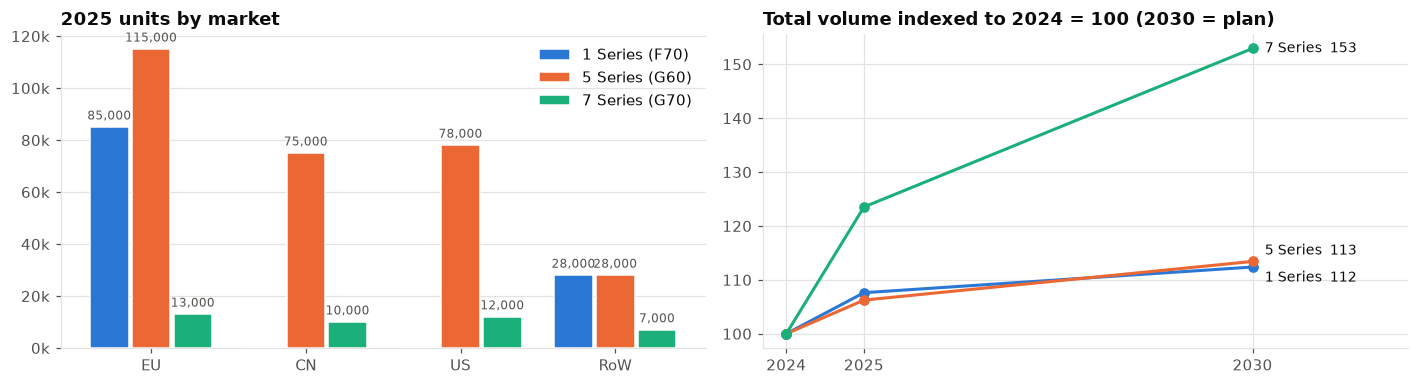

,volume_2024,volume_2025,volume_2030,growth_24_25,growth_25_30
series,,,,,
F70,"105,000","113,000","118,000",+8%,+4%
G60,"278,600","296,000","316,000",+6%,+7%
G70,"34,000","42,000","52,000",+24%,+24%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
pivot = sales.pivot_table(index="series", columns="market_code", values="volume_2025", aggfunc="sum")[MARKET_ORDER]
x = np.arange(len(MARKET_ORDER))
for i, code in enumerate(SERIES):
    axes[0].bar(x + (i - 1) * 0.27, pivot.loc[code], width=0.25, color=SERIES[code]["color"],
                label=f"{SERIES[code]['name']} ({code})", edgecolor="white")
axes[0].set_xticks(x, MARKET_ORDER)
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
axes[0].set_title("2025 units by market")
axes[0].legend()
axes[0].grid(axis="x", visible=False)
bar_labels(axes[0], "{:,.0f}")

totals = sales.groupby("series")[["volume_2024", "volume_2025", "volume_2030"]].sum()
indexed = totals.div(totals["volume_2024"], axis=0) * 100
for code in SERIES:
    axes[1].plot([2024, 2025, 2030], indexed.loc[code], color=SERIES[code]["color"], linewidth=2, marker="o", markersize=6)
    axes[1].annotate(f"{SERIES[code]['name']}  {indexed.loc[code, 'volume_2030']:.0f}", (2030, indexed.loc[code, "volume_2030"]),
                     xytext=(8, {"F70": -7, "G60": 7, "G70": 0}[code]), textcoords="offset points", va="center",
                     fontsize=9, color=INK)
axes[1].set_xticks([2024, 2025, 2030])
axes[1].set_xlim(2023.7, 2032)
axes[1].set_title("Total volume indexed to 2024 = 100 (2030 = plan)")
fig.tight_layout()
plt.show()

totals.assign(growth_24_25=totals.volume_2025 / totals.volume_2024 - 1,
              growth_25_30=totals.volume_2030 / totals.volume_2025 - 1).style.format(
    {"volume_2024": "{:,.0f}", "volume_2025": "{:,.0f}", "volume_2030": "{:,.0f}",
     "growth_24_25": "{:+.0%}", "growth_25_30": "{:+.0%}"})

---
## 3. BMW 1 Series (F70)

Front-wheel-drive premium compact hatch, ICE only (petrol and diesel, some 48 V mild hybrid). Sold only in Europe and the rest of the world.

### 3.1 Sales

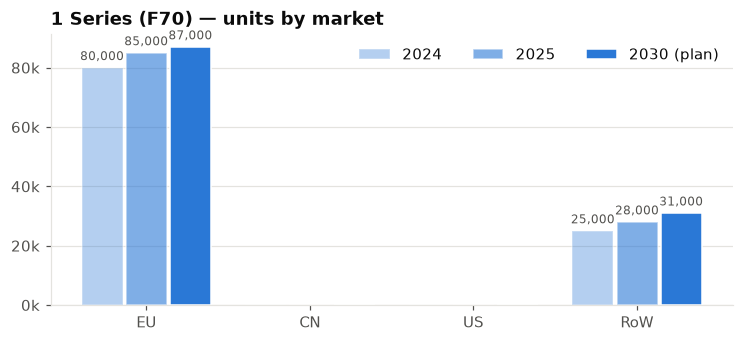

,volume_2024,volume_2025,volume_2030,growth_25_30,share_2025
market_code,,,,,
EU,"80,000","85,000","87,000",+2%,75%
CN,0,0,0,+nan%,0%
US,0,0,0,+nan%,0%
RoW,"25,000","28,000","31,000",+11%,25%
Total,"105,000","113,000","118,000",+4%,100%


In [9]:
plot_sales("F70")

### 3.2 Customer feedback

All F70 feedback is Source A (owner reviews), from GB and JP mainly.

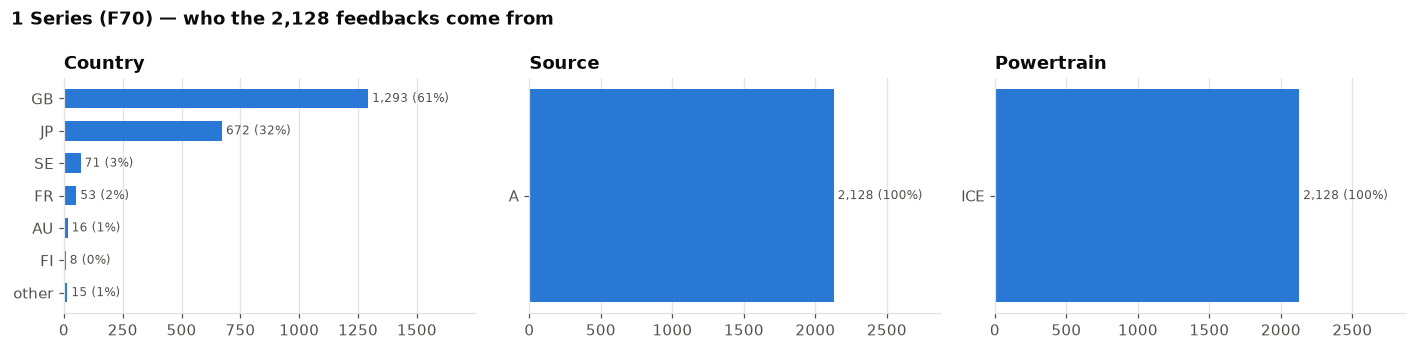

**Share of feedbacks tagged with each feedback type, by powertrain**

,feedbacks,Likes,Difficult to Use,Defect,Wants,unclassified
powertrain,,,,,,
ICE,"2,128",0.603383,0.217105,0.174812,0.117011,0.140977


In [10]:
feedback_profile("F70")

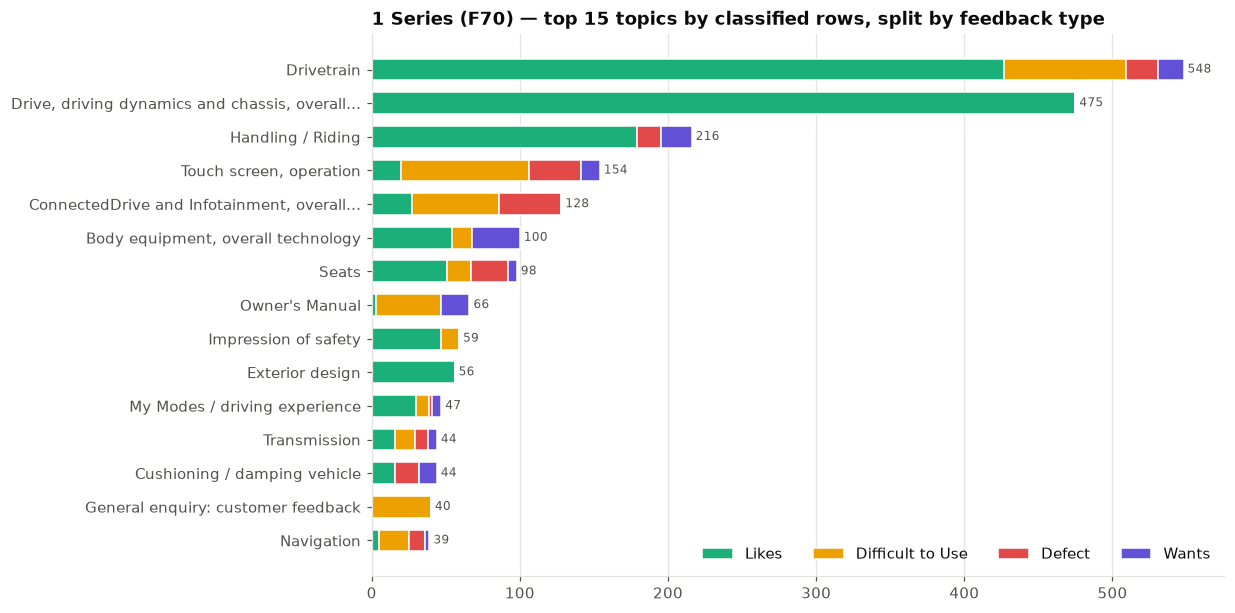

Most liked (Likes rows)      Biggest pain points (Difficult to Use + Defect rows)       \
                                                      topic rows                                                topic rows   
1   Drive, driving dynamics and chassis, overall technology  475                              Touch screen, operation  121   
2                                                Drivetrain  427                                           Drivetrain  104   
3                                         Handling / Riding  179  ConnectedDrive and Infotainment, overall technology  101   
4                                           Exterior design   56                                       Owner's Manual   44   
5                        Body equipment, overall technology   54                                                Seats   41   
6                                                     Seats   51                   General enquiry: customer feedback   40   
7                                      Impression of safety   47                                           Navigation   31   
8                             My Modes / driving experience   30                                    Audio mode, sound   24   
9       ConnectedDrive and Infotainment, overall technology   27                                         Transmission   22   
10                                          Interior design   26                                          Vehicle key   20   

              Most wanted (Wants rows)       
                                 topic rows  
1   Body equipment, overall technology   32  
2                    Handling / Riding   21  
3                       Owner's Manual   19  
4                           Drivetrain   17  
5              Touch screen, operation   13  
6      Engine acoustics / engine sound   13  
7         Cushioning / damping vehicle   12  
8             Exterior rearview mirror   10  
9             Vehicle, access and exit    9  
10          Space / spatial impression    8

**Most polarising topics (≥ 25 rows): lowest net sentiment**

ftype,Likes,Difficult to Use,Defect,Wants,total,net_sentiment
topic,,,,,,
General enquiry: customer feedback,0,40,0,0,40,-1.00
Wheels / tires,1,4,15,7,27,-0.93
Owner's Manual,3,44,0,19,66,-0.91
Navigation,5,20,11,3,39,-0.74
"Touch screen, operation",20,86,35,13,154,-0.74
"Audio mode, sound",6,2,22,6,36,-0.67
"ConnectedDrive and Infotainment, overall technology",27,59,42,0,128,-0.58
Exterior rearview mirror,8,3,14,10,35,-0.54
Braking,7,8,11,3,29,-0.52


In [11]:
plot_topics("F70")
topic_rankings("F70")

In [12]:
wants_detail("F70")
for topic in topic_table("F70").sort_values("pain", ascending=False).index[:3]:
    sample_verbatims("F70", topic)

**Wants: top topic × request type**

,,rows
topic,nature,
"Body equipment, overall technology",Dislike: price-performance ratio,23
Handling / Riding,Customer request: usability,21
Owner's Manual,Customer request: function,17
"Touch screen, operation",Customer request: usability,13
Drivetrain,Customer request: performance,13
Engine acoustics / engine sound,Customer request: sound,13
Cushioning / damping vehicle,Customer request: function,12
"Vehicle, access and exit",Customer request: function,9
Space / spatial impression,Customer request: space / spatial impression,8


**Touch screen, operation** — 119 critical feedbacks, sample:

- `F70-0767` (A, GB, ICE): my last car was a bmw 118 m sport (72 reg), which was excellent. the 120 is better than that one in lots of ways and i really enjoy driving it. the bigger control display is a plus, but i am unhappy that the idrive wheel has gone. having to do more by…
- `F70-1559` (A, GB, ICE): firm ride, which i kind of expected. engine reacts well with smooth automatic changes. cabin finish is excellent. the touch screen makes sense but is hard to use with a steady hand while driving. proper manuals should be given as there are many functions you…
- `F70-1560` (A, GB, ICE): the car is smooth to drive, relaxing and enjoyable, and it gives the impression of being a quality product. i am however disappointed that the idrive has gone and everything is pushed onto the touchscreen. please bring back physical controls for the climate…
- `F70-0112` (A, GB, ICE): i really like this car and would easily recommend it, it is a pleasure to drive. only thing is i want proper heating a/c buttons instead of all on the screen, and a dial for the screen too.

**Drivetrain** — 115 critical feedbacks, sample:

- `F70-0130` (A, JP, ICE): ride nothing in particular to mention about the fuel economy
- `F70-1398` (A, GB, ICE): i still havent got the handbook that explains all the things bmw promised. there are many functions i still dont use and displays on the panel that dont show what they actually control. what a con to charge extra to keep speed warnings after 2 months, i wasnt…
- `F70-1235` (A, GB, ICE): as a daily driver it is very nice and has plenty of punch when you ask for it, but as a sporty car it feels too sterile - very fast yet no character, no proper noise apart from the fake stuff. making everything run through the touch screen is a backwards step…
- `F70-0976` (A, GB, ICE): engine feels short on power whenever it is under strain.

**ConnectedDrive and Infotainment, overall technology** — 96 critical feedbacks, sample:

- `F70-0662` (A, GB, ICE): the car handles well, which was one of the main reasons for choosing my third bmw, along with the solid build quality. there should be more time spent showing how to use the controls and software. the materials are different compared to my previous one series…
- `F70-1850` (A, GB, ICE): lovely vehicle and simple to drive. but i dont find the computer system straightforward to use. i would like a handle inside the boot to pull the lid shut, as i am not very tall and that makes it challnging.
- `F70-0036` (A, GB, ICE): there are far too many technical features added which feel unnecessary and possibly dangerous. it seems to have lost its way that it is meant to be a car. standard useful and necessary items have been taken away or need to be reset every time you start a…
- `F70-1400` (A, GB, ICE): the infotainment has never worked right from day one. i raised a complaint but no fix has been given, so i keep checking for updates and just feel constantly fobbed off.

### 3.3 Customer study (EU only)

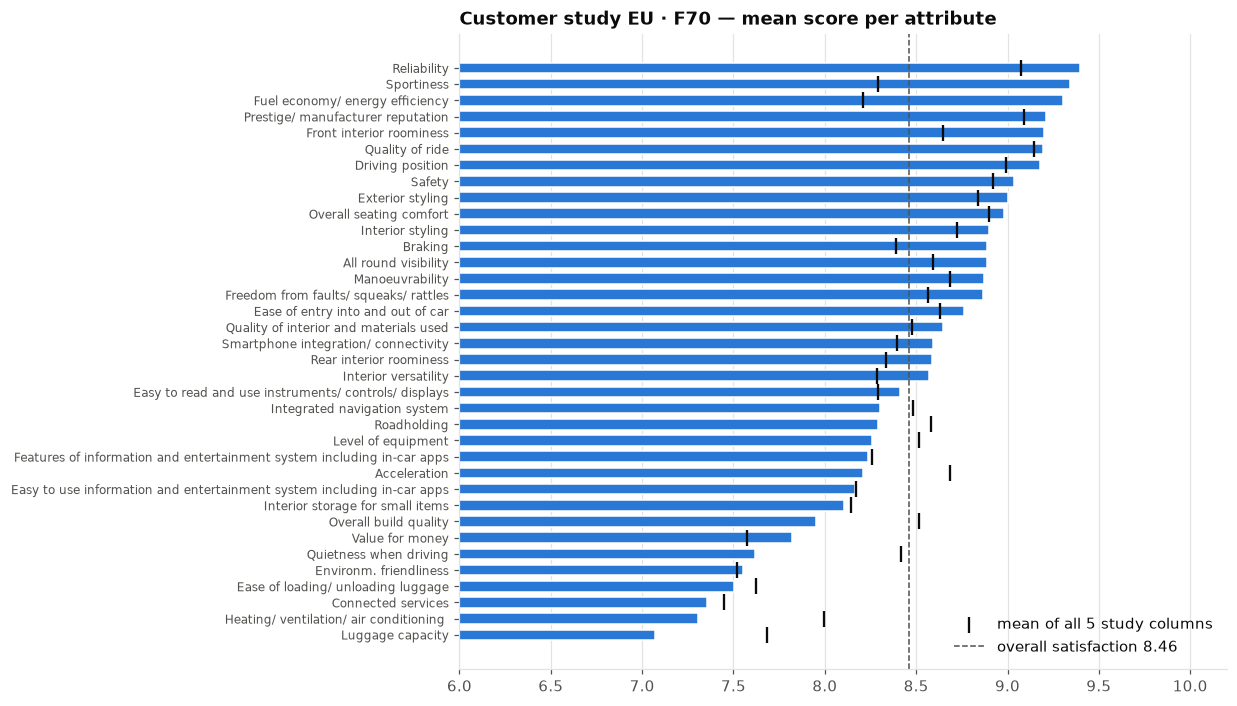

**EU · F70: weakest and strongest attributes** (gap = score minus the mean of the other four columns)

,score,rank (of 36),vs other columns,group
attribute,,,,
Luggage capacity,7.07,36,-0.76,weakest
Heating/ ventilation/ air conditioning,7.30,35,-0.86,weakest
Connected services,7.36,34,-0.12,weakest
Ease of loading/ unloading luggage,7.50,33,-0.15,weakest
Environm. friendliness,7.55,32,+0.04,weakest
Quietness when driving,7.62,31,-1.00,weakest
Reliability,9.40,1,+0.40,strongest
Sportiness,9.34,2,+1.31,strongest
Fuel economy/ energy efficiency,9.30,3,+1.37,strongest


In [13]:
study_cneu_profile("F70")

### 3.4 Equipment (German catalog)

In [14]:
equipment_profile("F70")

**Models in the German catalog (6)**

,Fuel / powertrain,Drive (p20),Output total kW (PS)²,"Base price EUR (""Fahrzeuggrundpreis"")"
Model,,,,
116,Benziner,Frontantrieb,90 (122),"34.250,– [28.781,51]"
120,"Benziner, 48 V mild hybrid",Frontantrieb,125 (170),"39.150,– [32.899,16]"
123 xDrive,"Benziner, 48 V mild hybrid",Allradantrieb (BMW xDrive),160 (218),"45.350,– [38.109,24]"
M135 xDrive,Benziner,Allradantrieb (BMW xDrive),221 (300),"57.150,– [48.025,21]"
118d,Diesel,Frontantrieb,110 (150),"39.350,– [33.067,23]"
120d,"Diesel, 48 V mild hybrid",Frontantrieb,120 (163),"41.750,– [35.084,03]"


**Equipment rows per model** (standard + optional equipment sections, 61 items; 0 models have no equipment data)

,116,120,123 xDrive,M135 xDrive,118d,120d
standard (S),30,30,30,37,30,30
optional (O),20,21,21,17,20,21
not offered (–),11,10,10,7,11,10


**Standard (S) items per category and model**

model,116,120,123 xDrive,M135 xDrive,118d,120d
category,,,,,,
Antrieb / Fahrdynamik / Fahrwerk,2,2,2,4,2,2
Exterieur,4,4,4,4,4,4
Fahrerassistenz und Sicherheit,8,8,8,9,8,8
Interieur,10,10,10,10,10,10
Komfort und Funktionalität,4,4,4,6,4,4
Konnektivität und Infotainment,2,2,2,4,2,2


**Trim ladder: 19 items that are standard on some models but not on others**

item 116 120 123 xDrive M135 xDrive 118d 120d
category                         code                                                                                                        
Exterieur                                                                     Lackierung Schwarz Uni   S   S          S           –    S    S
                                                                            Lackierung Alpinweiß Uni   –   –          –           S    –    –
                                                                 17" Leichtmetallräder Y-Speiche 971   S   S          S           –    S    S
                                                       18" Leichtmetallräder Y-Speiche 975 M Bicolor   –   –          –           S    –    –
Interieur                                                                     Stoff/Arktur Anthrazit   S   S          S           –    S    S
                                       M Alcantara/Veganza-Kombination Schwarz/Kontraststeppung Blau   –   –          –           S    –    –
                                                                        Interieurdekore dunkelsilber   S   S          S           –    S    S
                                              M Interieurdekore Illuminated Aluminium Hexacube, matt   –   –          –           S    –    –
                                                                 Seriensitz für Fahrer und Beifahrer   S   S          S           –    S    S
                                                                 Sportsitze für Fahrer und Beifahrer   –   –          –           S    –    –
Konnektivität und Infotainment                                 HiFi Lautsprechersystem harman/kardon   –   –          –           S    –    –
Antrieb / Fahrdynamik / Fahrwerk                                                Adaptives M Fahrwerk   –   –          –           S    –    –
                                                              Steptronic Getriebe mit Doppelkupplung   S   S          S           –    S    S
                                             Steptronic Getriebe mit Doppelkupplung und Schaltwippen   –   –          –           S    –    –
Fahrerassistenz und Sicherheit                                                Sonnenschutzverglasung   –   –          –           S    –    –
Antrieb / Fahrdynamik / Fahrwerk 2TE         Steptronic Getriebe mit Doppelkupplung und Schaltwippen   O   O          O           S    O    O
Konnektivität und Infotainment   674                           HiFi Lautsprechersystem harman/kardon   O   O          O           S    O    O
Komfort und Funktionalität       481                             Sportsitze für Fahrer und Beifahrer   O   O          O           S    O    O
                                 420                                          Sonnenschutzverglasung   O   O          O           S    O    O

### 3.5 Key observations: 1 Series

- **Europe-only car.** 113k units in 2025, 75 % in Europe, the rest RoW. Planned growth to 2030 is small (+4 %).
- **Feedback means UK and Japanese owner reviews** (61 % GB, 32 % JP, all Source A, all ICE). It says nothing about the continent, Germany or electrified drivetrains.
- **What owners love is the drive.** Driving dynamics, drivetrain and handling dominate Likes. The EU study agrees: sportiness (9.34), reliability (9.40) and fuel economy (9.30) are its top scores.
- **The main pain point is the touchscreen-only operation** (121 Difficult-to-Use/Defect rows, the most of any F70 topic), followed by infotainment and the missing paper owner's manual. Verbatims repeatedly ask for the iDrive dial and physical climate buttons back.
- **Practicality is the study's weak spot:** luggage capacity (7.07, lowest of all five CN/EU columns), HVAC (7.30), connected services (7.36) and ease of loading (7.50).
- **Equipment:** 6 ICE models with nearly identical standard equipment. The M135 xDrive is the only real step up the trim ladder.

---
## 4. BMW 5 Series (G60 sedan, G68 long wheelbase)

The volume car: ICE, PHEV and the battery-electric i5. G68 (long wheelbase, China) appears only in the China study and,
combined with G60, in the sales figures.

### 4.1 Sales (G60 + G68 combined)

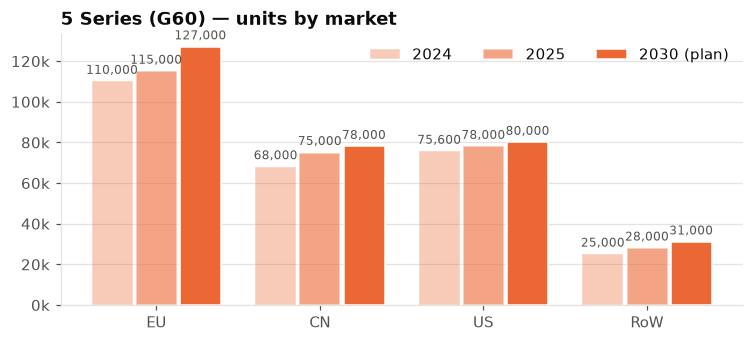

,volume_2024,volume_2025,volume_2030,growth_25_30,share_2025
market_code,,,,,
EU,"110,000","115,000","127,000",+10%,39%
CN,"68,000","75,000","78,000",+4%,25%
US,"75,600","78,000","80,000",+3%,26%
RoW,"25,000","28,000","31,000",+11%,9%
Total,"278,600","296,000","316,000",+7%,100%


In [15]:
plot_sales("G60")

### 4.2 Customer feedback (G60)

Mostly US (Sources B, C and D are US-only), with a few hundred Source A reviews from KR, JP and Europe.

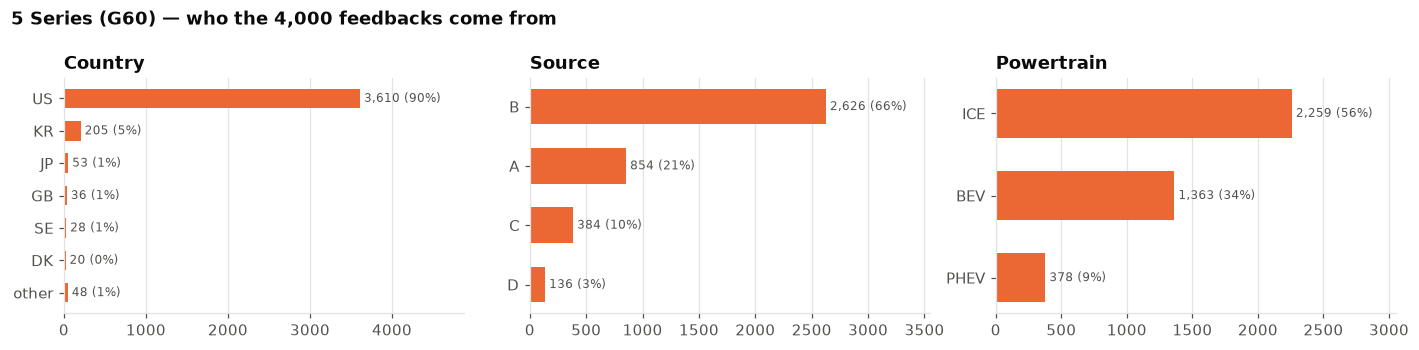

**Share of feedbacks tagged with each feedback type, by powertrain**

,feedbacks,Likes,Difficult to Use,Defect,Wants,unclassified
powertrain,,,,,,
BEV,"1,363",0.424065,0.300073,0.107117,0.151137,0.115187
ICE,"2,259",0.462151,0.303674,0.074812,0.120850,0.109783
PHEV,378,0.447090,0.306878,0.082011,0.153439,0.108466


In [16]:
feedback_profile("G60")

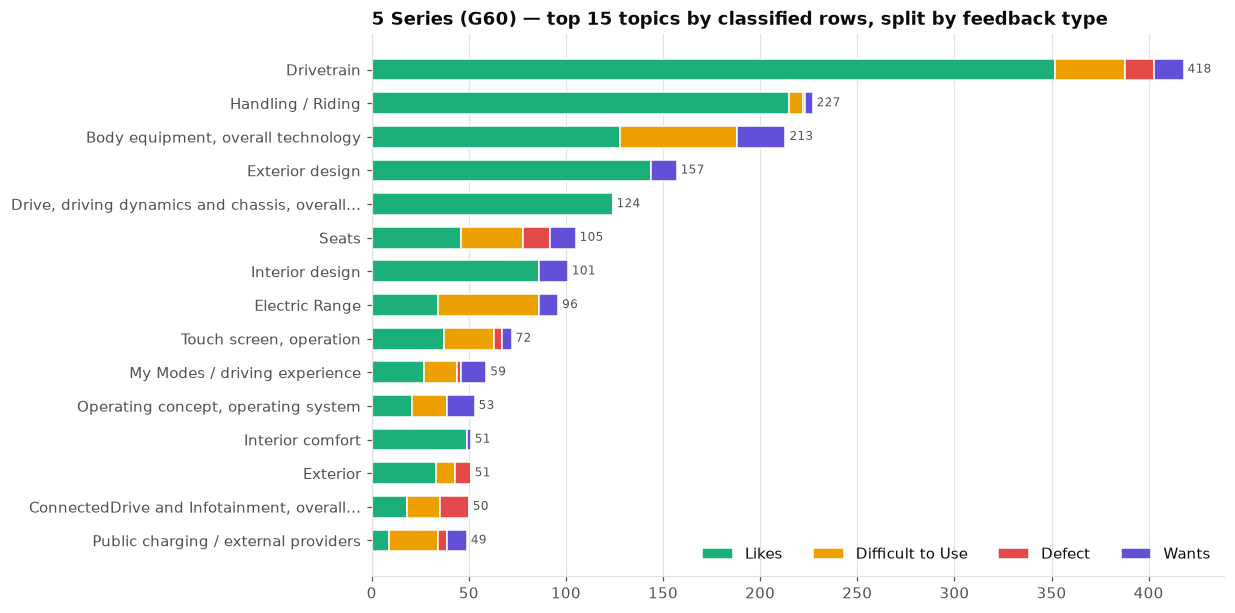

Most liked (Likes rows)      Biggest pain points (Difficult to Use + Defect rows)       \
                                                      topic rows                                                topic rows   
1                                                Drivetrain  352                   Body equipment, overall technology   60   
2                                         Handling / Riding  215                                       Electric Range   52   
3                                           Exterior design  144                                           Drivetrain   51   
4                        Body equipment, overall technology  128                                                Seats   46   
5   Drive, driving dynamics and chassis, overall technology  124                        non-contact trunk lid opening   40   
6                                           Interior design   86                                        Apple CarPlay   33   
7                                          Interior comfort   49  ConnectedDrive and Infotainment, overall technology   32   
8                                                     Seats   46                 Public charging / external providers   30   
9                                   Touch screen, operation   37                              Touch screen, operation   30   
10                                           Electric Range   34                                              Braking   28   

                      Most wanted (Wants rows)       
                                         topic rows  
1           Body equipment, overall technology   25  
2                                   Drivetrain   15  
3                              Interior design   15  
4          Operating concept, operating system   14  
5                                        Seats   13  
6                My Modes / driving experience   13  
7                              Exterior design   13  
8                                Ambient light   13  
9                          Panorama glass roof   12  
10  Automatic engine start-stop function (MSA)   11

**Most polarising topics (≥ 25 rows): lowest net sentiment**

ftype,Likes,Difficult to Use,Defect,Wants,total,net_sentiment
topic,,,,,,
non-contact trunk lid opening,2,39,1,1,43,-0.91
Automatic engine start-stop function (MSA),2,22,2,11,37,-0.89
"Vehicle, lock / unlock",2,22,5,4,33,-0.88
"Door, open / close",2,13,8,9,32,-0.88
"Mobile device, wireless charging",3,10,11,5,29,-0.79
Panorama glass roof,4,4,6,12,26,-0.69
"Vehicle, climatization",4,14,3,5,26,-0.69
Comfort Access,4,10,2,9,25,-0.68
"Center console, front",5,13,4,6,28,-0.64


In [17]:
plot_topics("G60")
topic_rankings("G60")

In [18]:
wants_detail("G60")
source_c_severity("G60")
for topic in topic_table("G60").sort_values("pain", ascending=False).index[:3]:
    sample_verbatims("G60", topic)

**Wants: top topic × request type**

,,rows
topic,nature,
"Body equipment, overall technology",Dislike: price-performance ratio,17
"Operating concept, operating system",Customer request: usability,14
Exterior design,Customer request: design,13
Drivetrain,Customer request: performance,11
Automatic engine start-stop function (MSA),Permanent switch-off not possible,10
Electric Range,Customer request: function,10
Interior design,Customer request: design,10
Panorama glass roof,Customer request: function,9
Ambient light,Customer request: function,9


**Source C problem reports: 235 of 384 Source C feedbacks state a severity**

severity,very minor,minor,serious,very serious
feedbacks,50,84,64,37


Items with the most *serious / very serious* problems:

item,Front heating/cooling controls/vents,Trunk/hatch/tailgate,Automatic engine stop-start,EV/plug-in hybrid,Glove box,Built-in Wi-Fi,Touchscreen/display screen,Engine/motor doesn't start/turn on at all,Door locks,Charging door/cap
feedbacks,6,4,4,4,3,3,3,3,2,2


**Body equipment, overall technology** — 85 critical feedbacks, sample:

- `G60-0176` (B, US, BEV): Customer stated she is still getting familiar with the vehicle. Customer stated there is a lot to take in. Writer asked if she currently had any questions. Customer stated nothing in particular at this time.
- `G60-0667` (B, US, ICE): Customer shared that she still needs to figure out a lot of features that she currently does not know how to operate. Customer said she intends to go online and consult the manual. Writer asked her which items she is specifically interested in. Customer…
- `G60-3217` (B, US, ICE): Customer stated that overall the tech in the car is challenging to pick up. Customer stated he currently does not have any questions about the technology.
- `G60-2108` (A, KR, ICE): the price is far higher than the 520i, so i only rate it 9 points otherwise. the ride works well for fundraising, and both the appearance configuration and the overall design are satisfying.

**Electric Range** — 61 critical feedbacks, sample:

- `G60-1967` (B, US, BEV): Customer stated he would like the vehicle to offer more range on a charge. Customer stated that having a range of over 400 miles would be awesome for him.
- `G60-2424` (A, DK, BEV): the apps built into the car really ought to be reachable from the phone, so you don't have to sit in the car and fiddle with them - you can do that in a mercedes, which was my previous car. the windows also can't be closed via the app, while mercedes manages…
- `G60-3978` (B, US, PHEV): Customer commented that he believes the electric driving range should definitely be much longer.
- `G60-1993` (A, US, BEV): driving the car is good, no complaints there. but charging options in south carolina are bad, especially since i can't use the tesla supercharger network. in cold weather, below about 32 degrees fahrenheit, the battery range drops down to roughly 200 miles…

**Drivetrain** — 66 critical feedbacks, sample:

- `G60-3051` (A, KR, PHEV): the gas mileage is worse than i expected, pretty much matching the grandeur ig hybrid i currently drive, instead of being better.
- `G60-2026` (A, US, PHEV): overall the experience has been very positive, the tech feels solid and the highway "self-driving" is much better than the last generation. i would like finer control over the sport mode settings. i also want clearer guidance on how to use the engine when…
- `G60-2185` (A, US, ICE): really happy with the ride, the way it handles, and the powertrain. the 19 inch wheels/tires are terrific, much better overall than the wider low-profile setup. the only thing that could beat it would be the v8 that was in the 550. not having the old-style…
- `G60-3472` (B, US, PHEV): Customer stated the car was sold to them as a hybrid, but in actual use it runs purely on electric power for an initial number of miles and then, once that range is depleted, which happens within the same day if they drive more than about 30 miles, it…

### 4.3 Customer study — EU (G60) and China (G68)

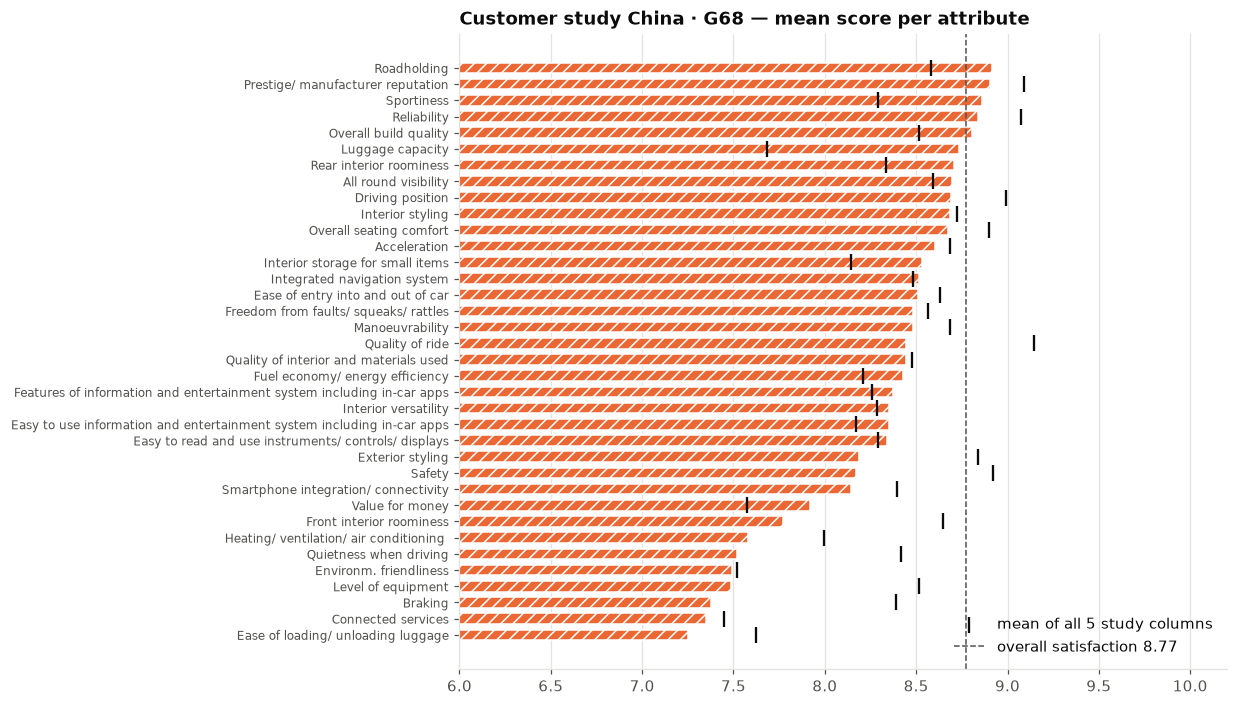

**China · G68: weakest and strongest attributes** (gap = score minus the mean of the other four columns)

,score,rank (of 36),vs other columns,group
attribute,,,,
Ease of loading/ unloading luggage,7.25,36,-0.47,weakest
Connected services,7.35,35,-0.13,weakest
Braking,7.38,34,-1.26,weakest
Level of equipment,7.49,33,-1.28,weakest
Environm. friendliness,7.49,32,-0.03,weakest
Quietness when driving,7.52,31,-1.13,weakest
Roadholding,8.92,1,+0.42,strongest
Prestige/ manufacturer reputation,8.90,2,-0.23,strongest
Sportiness,8.86,3,+0.71,strongest


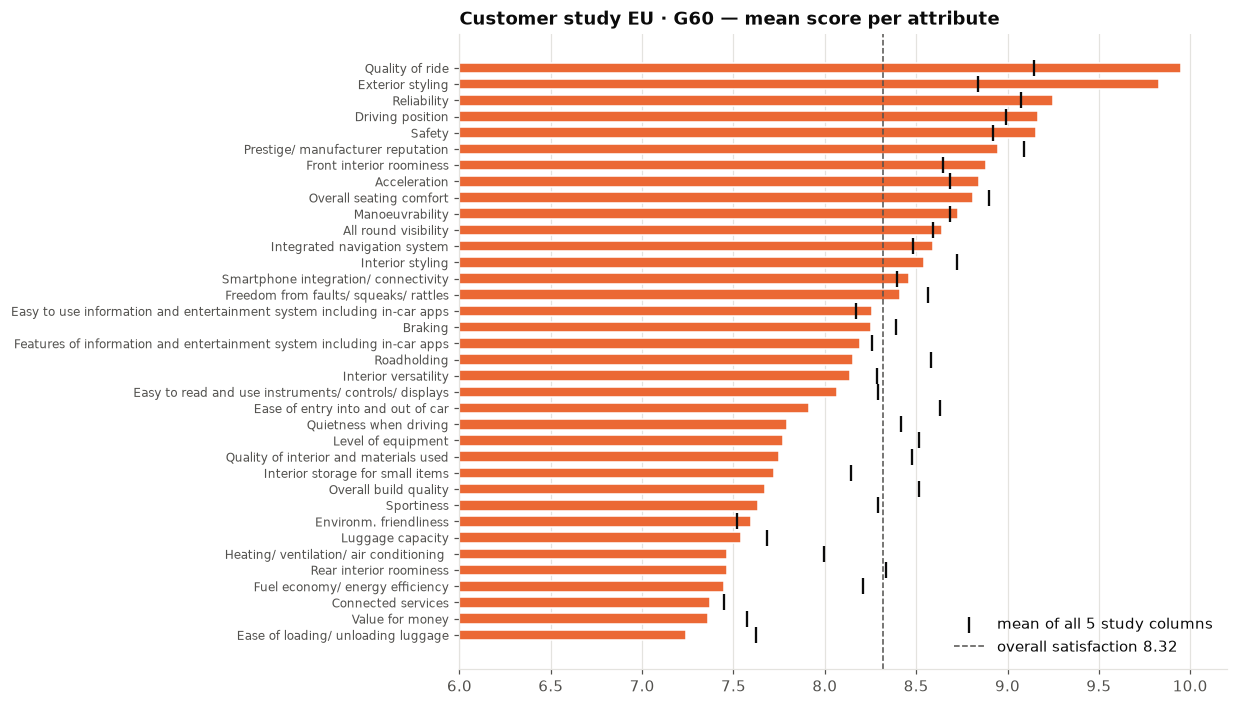

**EU · G60: weakest and strongest attributes** (gap = score minus the mean of the other four columns)

,score,rank (of 36),vs other columns,group
attribute,,,,
Ease of loading/ unloading luggage,7.24,36,-0.48,weakest
Value for money,7.36,35,-0.26,weakest
Connected services,7.37,34,-0.10,weakest
Fuel economy/ energy efficiency,7.45,33,-0.95,weakest
Rear interior roominess,7.46,32,-1.09,weakest
Heating/ ventilation/ air conditioning,7.47,31,-0.66,weakest
Quality of ride,9.95,1,+1.00,strongest
Exterior styling,9.83,2,+1.24,strongest
Reliability,9.25,3,+0.22,strongest


In [19]:
study_cneu_profile("G60")

### 4.4 Customer study — US (G60)

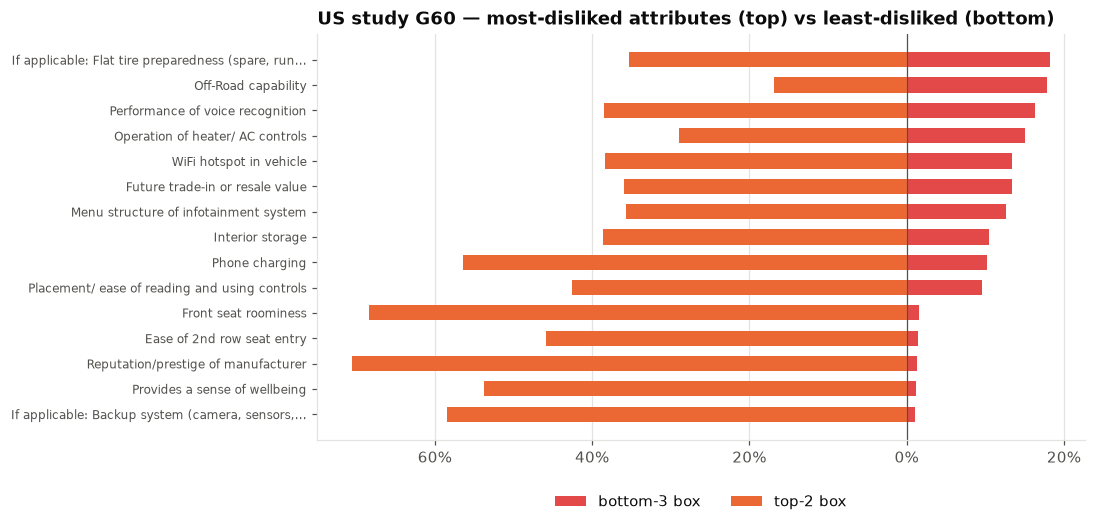

**US G60: lowest weighted mean (1–7)**, with the top-2 gap vs the G70

,mean_1_7,top2,bottom3,top2_vs_other
attribute,,,,
Off-Road capability,4.53,17%,17.9%,-10%
"If applicable: Flat tire preparedness (spare, run flat, etc.)",4.68,35%,18.2%,+8%
Affordable to buy,4.70,20%,8.0%,+13%
Operation of heater/ AC controls,4.80,29%,15.0%,-3%
Menu structure of infotainment system,4.88,36%,12.6%,+4%
Future trade-in or resale value,4.92,36%,13.4%,+23%
Economical to own (cost of ownership),4.97,28%,6.8%,+12%
WiFi hotspot in vehicle,4.98,38%,13.4%,+10%
Performance of voice recognition,4.99,38%,16.3%,+2%


In [20]:
study_us_profile("G60")

### 4.5 Equipment (German catalog, G60 sedan)

In [21]:
equipment_profile("G60")

**Models in the German catalog (10)**

,Fuel / powertrain,Drive,System output kW (PS),Battery / electric range (WLTP),Base price EUR [net]
Model,,,,,
i5 eDrive40,"Vollelektrisch (BEV), 1 E-Motor",Hinterradantrieb,250 (340),"81,2 kWh net / 513 – 627 km","70.900,– [59.579,83]"
i5 xDrive40,"Vollelektrisch (BEV), 2 E-Motoren",Allradantrieb,290 (394),"81,2 kWh net / 487 – 581 km","76.300,– [64.117,65]"
i5 M60 xDrive,"Vollelektrisch (BEV), 2 E-Motoren",Allradantrieb,442 (601),"81,2 kWh net / 473 – 539 km","100.200,– [84.201,68]"
530e,Benzin Plug-in-Hybrid (PHEV),Hinterradantrieb,220 (299),"19,4 kWh net / 95 – 105 km","66.700,– [56.050,42]"
530e xDrive,Benzin Plug-in-Hybrid (PHEV),Allradantrieb,220 (299),"19,4 kWh net / 84 – 95 km","69.300,– [58.235,29]"
550e xDrive,Benzin Plug-in-Hybrid (PHEV),Allradantrieb,360 (489),"19,0 kWh net / 85 – 93 km","78.700,– [66.134,45]"
520i,"Benzin, 48 V Mild-Hybrid",Hinterradantrieb,153 (208),"0,9 kWh gross (48 V) / –","60.000,– [50.420,17]"
520d,"Diesel, 48 V Mild-Hybrid",Hinterradantrieb,145 (197),"0,9 kWh gross (48 V) / –","62.300,– [52.352,94]"
520d xDrive,"Diesel, 48 V Mild-Hybrid",Allradantrieb,145 (197),"0,9 kWh gross (48 V) / –","64.900,– [54.537,82]"


**Equipment rows per model** (standard + optional equipment sections, 72 items; 0 models have no equipment data)

,i5 eDrive40,i5 xDrive40,i5 M60 xDrive,530e,530e xDrive,550e xDrive,520i,520d,520d xDrive,540d xDrive
standard (S),35,37,46,36,36,38,33,33,33,33
optional (O),22,22,19,21,21,21,22,22,22,22
not offered (–),15,13,7,15,15,13,17,17,17,17


**Standard (S) items per category and model**

model,i5 eDrive40,i5 xDrive40,i5 M60 xDrive,530e,530e xDrive,550e xDrive,520i,520d,520d xDrive,540d xDrive
category,,,,,,,,,,
Antrieb / Fahrdynamik / Fahrwerk,2,4,5,3,3,5,1,1,1,1
Exterieur,2,2,4,2,2,2,2,2,2,2
Fahrerassistenz und Sicherheit,11,11,11,11,11,11,10,10,10,10
Interieur,3,3,4,3,3,3,3,3,3,3
Klimakomfort,0,0,1,0,0,0,0,0,0,0
Komfort und Funktionalität,9,9,11,9,9,9,9,9,9,9
Konnektivität und Infotainment,8,8,8,8,8,8,8,8,8,8
M Sportpaket Pro,0,0,1,0,0,0,0,0,0,0
Weitere Funktionen,0,0,1,0,0,0,0,0,0,0


**Trim ladder: 24 items that are standard on some models but not on others**

item i5 eDrive40 i5 xDrive40 i5 M60 xDrive 530e  \
category                         code                                                                                                                      
M Sportpaket Pro                 33B      M SPORTPAKET PRO — M Leuchten Shadow Line; M Hochglanz Shadow Line…           –           –             S    –   
Exterieur                        3FY   18" Leichtmetallräder Y-Speiche 932 — 7,5J x 18 mit Bereifung 225/55,…           –           –             –    –   
                                 3G0     19" Leichtmetallräder Triplex-Speiche 933 — 8,5J x 19 mit Bereifung…           S           S             –    S   
                                 3G9                 19" M Leichtmetallräder Doppelspeiche 935 M Bicolor mit…           –           –             S    –   
                                 3DP                                           BMW Iconic Glow Exterieurpaket           –           –             S    –   
Interieur                        KUSW                                    Polster Veganza perforiert | Schwarz           S           S             –    S   
                                 KTSW                                             M Veganza/Alcantara Schwarz           –           –             S    –   
                                 43G    Interieurleisten Akzent Dunkelsilber kombiniert mit Effektlackierung…           S           S             –    S   
                                 43R         Interieurleisten M Akzent Dunkelsilber kombiniert mit Aluminium…           –           –             S    –   
                                 775                                                   M Dachhimmel Anthrazit           –           –             S    –   
Antrieb / Fahrdynamik / Fahrwerk                                         Steptronic Getriebe mit Schaltwippen           –           –             –    S   
                                 2VV                                          Adaptives Fahrwerk Professional           –           S             S    –   
                                 4V1                                                BMW IconicSounds Electric           S           S             S    S   
                                                       Ladekabel Professional (Mode 3) für öffentliches Laden           S           S             S    S   
                                 4U6                                            AC-Laden Professional (22 kW)           –           –             S    –   
Fahrerassistenz und Sicherheit                                                    Akustischer Fußgängerschutz           S           S             S    S   
Komfort und Funktionalität                                                                     Klimaautomatik           S           S             –    S   
                                 4NB                                       Klimaautomatik mit 4-Zonenregelung           –           –             S    –   
                                 459                   Sitzverstellung, elektrisch, mit Memory für Fahrersitz           –           –             S    –   
                                 710                                                           M Lederlenkrad           –           –             S    –   
Exterieur                        3DP                                           BMW Iconic Glow Exterieurpaket           O           O             S    O   
Antrieb / Fahrdynamik / Fahrwerk 2VV   Adaptives Fahrwerk Professional — Elektronisch geregelte Stoßdämpfer;…           O           S             S    O   
Klimakomfort                     420                                                   Sonnenschutzverglasung           O           O             S    O   
Weitere Funktionen               4U6                                            AC-Laden Professional (22 kW)           O           O             S    –   

                                      530e xDriv

### 4.6 Key observations: 5 Series

- **The volume car.** 296k units in 2025, split EU 39 % · US 26 % · CN 25 % · RoW 9 %. Planned growth to 2030 is +7 %. The China volume is the long-wheelbase G68, for which there is study data but no feedback.
- **Feedback is ~90 % US** and mostly Source B (dealer/call-centre paraphrases). The ICE/BEV/PHEV mix lets us look at electrified-drivetrain topics.
- **Loved:** drivetrain, handling, exterior design. EU study peaks are quality of ride (9.95) and exterior styling (9.83).
- **Pain points:** overall tech complexity ("a lot to take in"), electric range, seats, non-contact trunk opening, Apple CarPlay and public charging. Range and charging topics are concentrated in BEV feedback (section 6.4).
- **Wants:** a more usable operating concept, exterior design changes, and a permanent switch-off for auto start-stop.
- **Studies:** EU weak spots are luggage loading (7.24), value for money (7.36), connected services (7.37) and fuel economy (7.45). China G68 is weak on luggage loading, connected services, braking and level of equipment (7.49, vs 9.82 for the G70 in China). The US bottom-3 boxes point at heater/AC controls, Wi-Fi hotspot, the infotainment menu structure and interior storage.

---
## 5. BMW 7 Series (G70)

The flagship: ICE, PHEV and the battery-electric i7. Small in volume but balanced across EU, CN and US, with study data in all three.

### 5.1 Sales

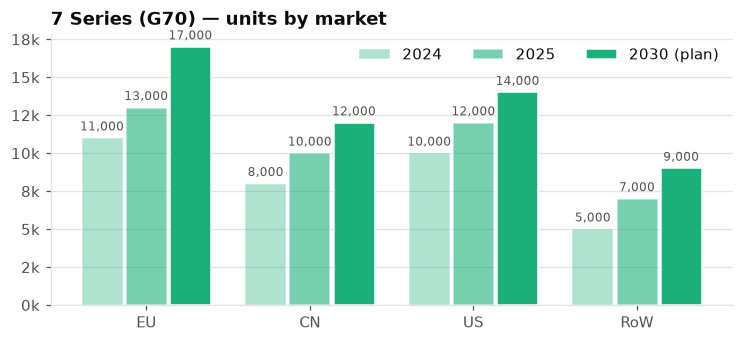

,volume_2024,volume_2025,volume_2030,growth_25_30,share_2025
market_code,,,,,
EU,"11,000","13,000","17,000",+31%,31%
CN,"8,000","10,000","12,000",+20%,24%
US,"10,000","12,000","14,000",+17%,29%
RoW,"5,000","7,000","9,000",+29%,17%
Total,"34,000","42,000","52,000",+24%,100%


In [22]:
plot_sales("G70")

### 5.2 Customer feedback

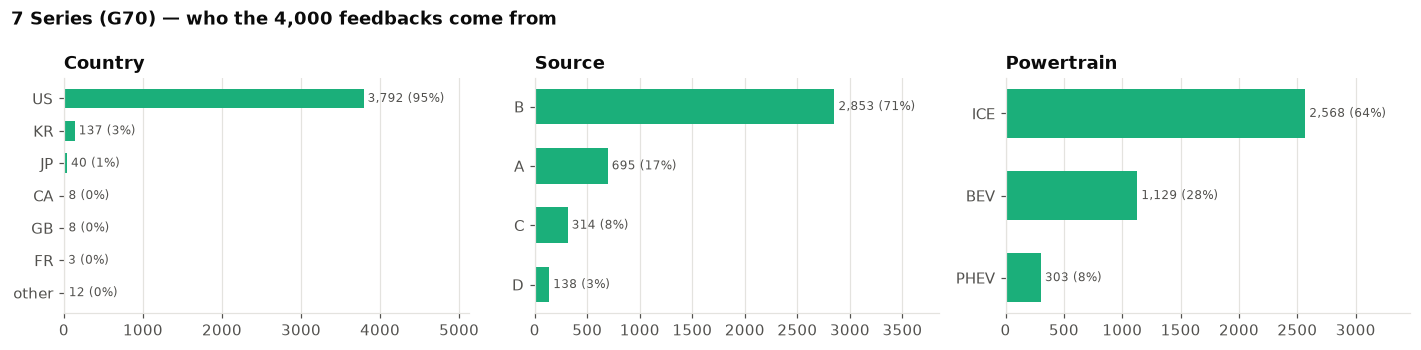

**Share of feedbacks tagged with each feedback type, by powertrain**

,feedbacks,Likes,Difficult to Use,Defect,Wants,unclassified
powertrain,,,,,,
BEV,"1,129",0.435784,0.284322,0.095660,0.131975,0.108946
ICE,"2,568",0.450935,0.255841,0.099299,0.117991,0.116044
PHEV,303,0.448845,0.290429,0.108911,0.115512,0.102310


In [23]:
feedback_profile("G70")

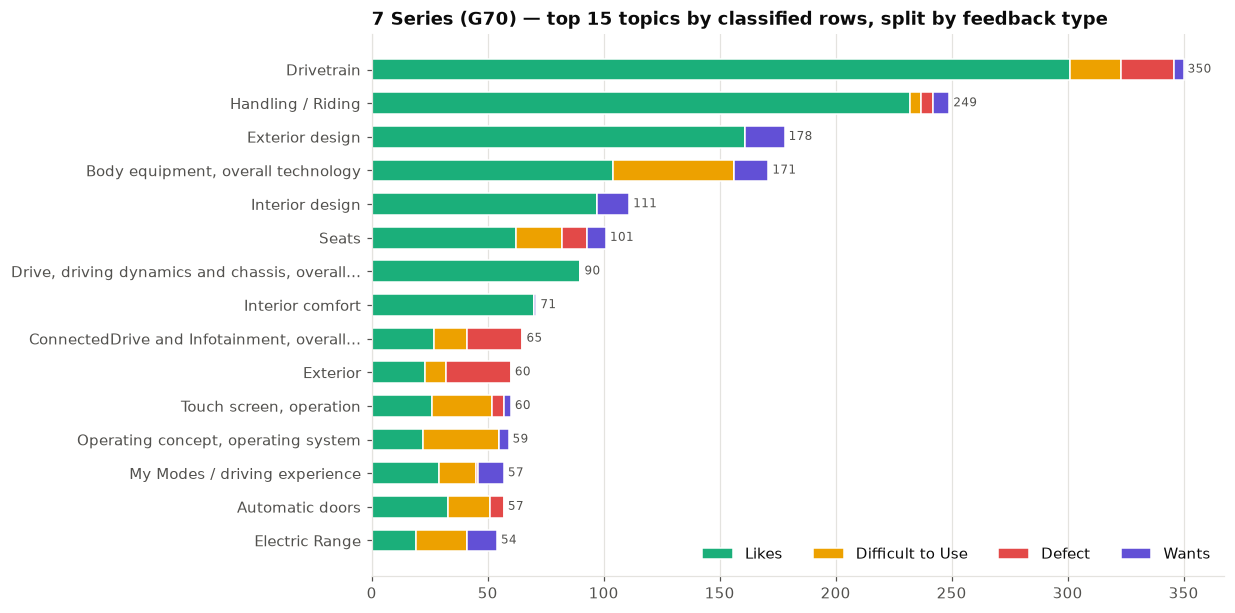

Most liked (Likes rows)      Biggest pain points (Difficult to Use + Defect rows)       \
                                                      topic rows                                                topic rows   
1                                                Drivetrain  301                   Body equipment, overall technology   52   
2                                         Handling / Riding  232                                           Drivetrain   45   
3                                           Exterior design  161  ConnectedDrive and Infotainment, overall technology   38   
4                        Body equipment, overall technology  104                               Vehicle, climatization   38   
5                                           Interior design   97                                             Exterior   37   
6   Drive, driving dynamics and chassis, overall technology   90                                        Personal eSIM   37   
7                                          Interior comfort   70                  Operating concept, operating system   33   
8                                                     Seats   62                                                Seats   31   
9                                Space / spatial impression   38                              Touch screen, operation   31   
10                                          Automatic doors   33                                My BMW App / MINI App   26   

                      Most wanted (Wants rows)       
                                         topic rows  
1                               Wheels / tires   19  
2                              Exterior design   17  
3           Body equipment, overall technology   15  
4                          Panorama glass roof   14  
5                              Interior design   14  
6                               Electric Range   13  
7   Automatic engine start-stop function (MSA)   13  
8                My Modes / driving experience   11  
9                     Interior rearview mirror   11  
10                                Seat massage    9

**Most polarising topics (≥ 25 rows): lowest net sentiment**

ftype,Likes,Difficult to Use,Defect,Wants,total,net_sentiment
topic,,,,,,
Personal eSIM,1,26,11,2,40,-0.95
"Vehicle, climatization",2,32,6,4,44,-0.91
Automatic engine start-stop function (MSA),3,16,2,13,34,-0.82
"Door, open / close",3,13,7,9,32,-0.81
Sun protection,3,11,4,8,26,-0.77
Apple CarPlay,4,17,7,1,29,-0.72
Public charging / external providers,4,14,4,7,29,-0.72
Braking,6,15,6,7,34,-0.65
My BMW App / MINI App,6,24,2,2,34,-0.65


In [24]:
plot_topics("G70")
topic_rankings("G70")

In [25]:
wants_detail("G70")
source_c_severity("G70")
for topic in topic_table("G70").sort_values("pain", ascending=False).index[:3]:
    sample_verbatims("G70", topic)

**Wants: top topic × request type**

,,rows
topic,nature,
Exterior design,Customer request: design,17
Electric Range,Customer request: function,13
Panorama glass roof,Customer request: function,13
Interior design,Customer request: design,12
Interior rearview mirror,Customer request: function,11
Wheels / tires,Customer request: design,11
Automatic engine start-stop function (MSA),Permanent switch-off not possible,10
"Body equipment, overall technology",Dislike: price-performance ratio,10
Wheels / tires,Customer request: function,8


**Source C problem reports: 183 of 314 Source C feedbacks state a severity**

severity,very minor,minor,serious,very serious
feedbacks,38,51,48,46


Items with the most *serious / very serious* problems:

item,OEM smartphone app,Engine/motor doesn't start/turn on at all,Memory seats,Touchscreen/display screen,Front heating/cooling controls/vents,Built-in voice recognition,Built-in Wi-Fi,Built-in navigation system,Interior light controls,Door panels
feedbacks,7,4,4,4,3,3,3,2,2,2


**Body equipment, overall technology** — 67 critical feedbacks, sample:

- `G70-1929` (B, US, BEV): Customer indicated the sole downside of this vehicle is that it feels like "dizzying digital". Customer added that being so heavily digital makes it harder to operate and can be overwhelming at times.
- `G70-3400` (A, US, ICE): the car just does everything perfectly. ride and handling are excellent, best v6 i've ever driven. it's basically like a rolls royce ghost while being about 300% cheaper.
- `G70-2266` (B, US, ICE): Customer stated she is still figuring out how to use everything. Writer offered assistance. Customer stated she is busy at the moment. Writer invited the customer to get back in touch later.
- `G70-2114` (B, US, ICE): Customer stated the car is a little complicated for them given their age, but they are gradually figuring it out. Writer asked if they needed help with anything in particular. Customer declined assistance.

**Drivetrain** — 47 critical feedbacks, sample:

- `G70-2353` (B, US, ICE): Customer stated the vehicle began misfiring last week and a check engine light showed up briefly and then disappeared again.
- `G70-2686` (B, US, ICE): Customer stated the V8 engine leads to increased fuel use and therefore higher gas costs, but indicated this is an expected and acceptable characteristic.
- `G70-2514` (B, US, ICE): Customer reported she needed to take the vehicle in because the ozone computer was not functioning, which was keeping the check engine light on. DCS service notes: 146 miles., Defect Code: 1178031400 Defect Description: Oxygen monitor sensor occasional…
- `G70-0398` (B, US, ICE): Customer stated his car has been sitting in the dealer's service department since around 1/8, and it has basically been out of his hands this whole time. Customer stated the dealer, while running remote diagnostic checks, picked up an issue with the air and…

**ConnectedDrive and Infotainment, overall technology** — 36 critical feedbacks, sample:

- `G70-3358` (A, US, ICE): i'm really unhappy with the self driving functions on this car. i paid more for this 7 series than for my previous one and ended up with fewer features. i believed it came with automatic traffic stop-and-go where it would handle heavy traffic on its own, and…
- `G70-1900` (A, US, ICE): could use extra storage space around the dash for random items. the seat belt should be improved. the music station software keeps switching on its own and will not hold the last channel spot.
- `G70-1620` (B, US, ICE): Customer stated she had dash problems in her previous X6 and chose the 7 Series thinking a more premium model would be free of such issues, but the same type of problem is happening. Customer stated the dash display went completely black around three times…
- `G70-3228` (A, US, ICE): the car is very comfortable and feels up to date, but i have had way too many issues in a short period. i like the interior styling, yet a lot of the nice features are buried and take forever to access. there really should be simple buttons to open and close…

### 5.3 Customer study — EU and China

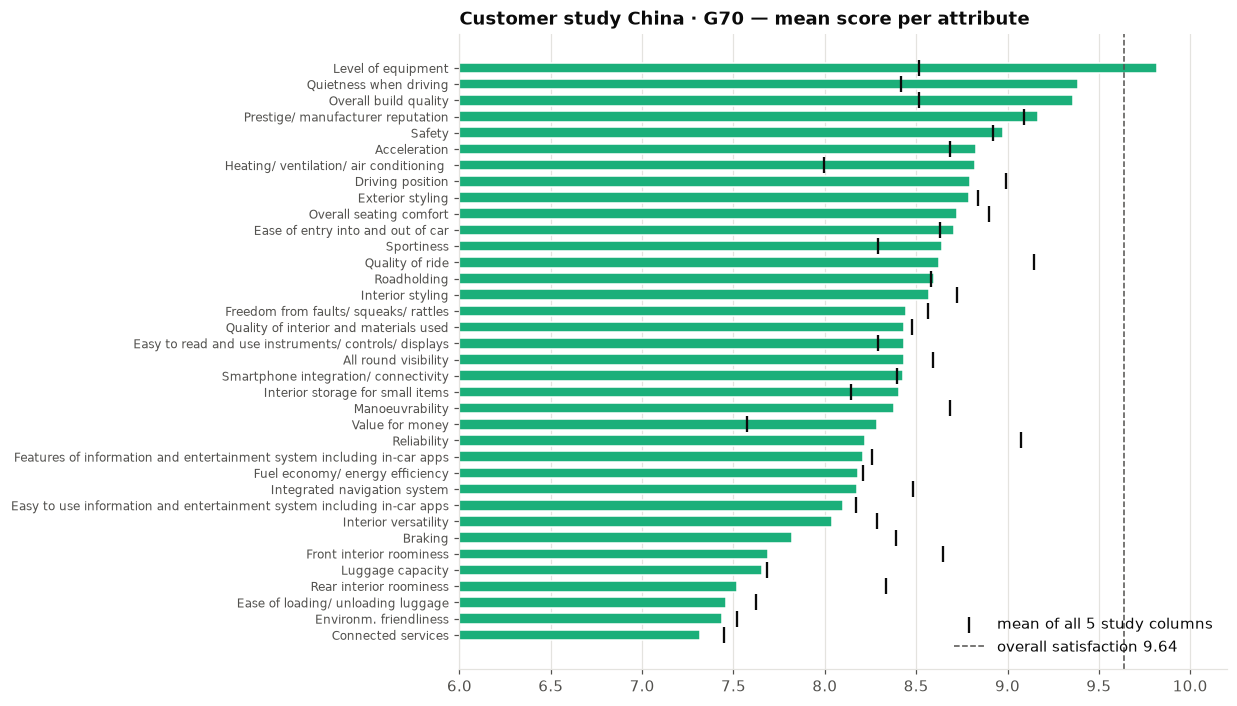

**China · G70: weakest and strongest attributes** (gap = score minus the mean of the other four columns)

,score,rank (of 36),vs other columns,group
attribute,,,,
Connected services,7.32,36,-0.17,weakest
Environm. friendliness,7.44,35,-0.10,weakest
Ease of loading/ unloading luggage,7.46,34,-0.21,weakest
Rear interior roominess,7.52,33,-1.02,weakest
Luggage capacity,7.66,32,-0.03,weakest
Front interior roominess,7.69,31,-1.20,weakest
Level of equipment,9.82,1,+1.63,strongest
Quietness when driving,9.39,2,+1.21,strongest
Overall build quality,9.36,3,+1.06,strongest


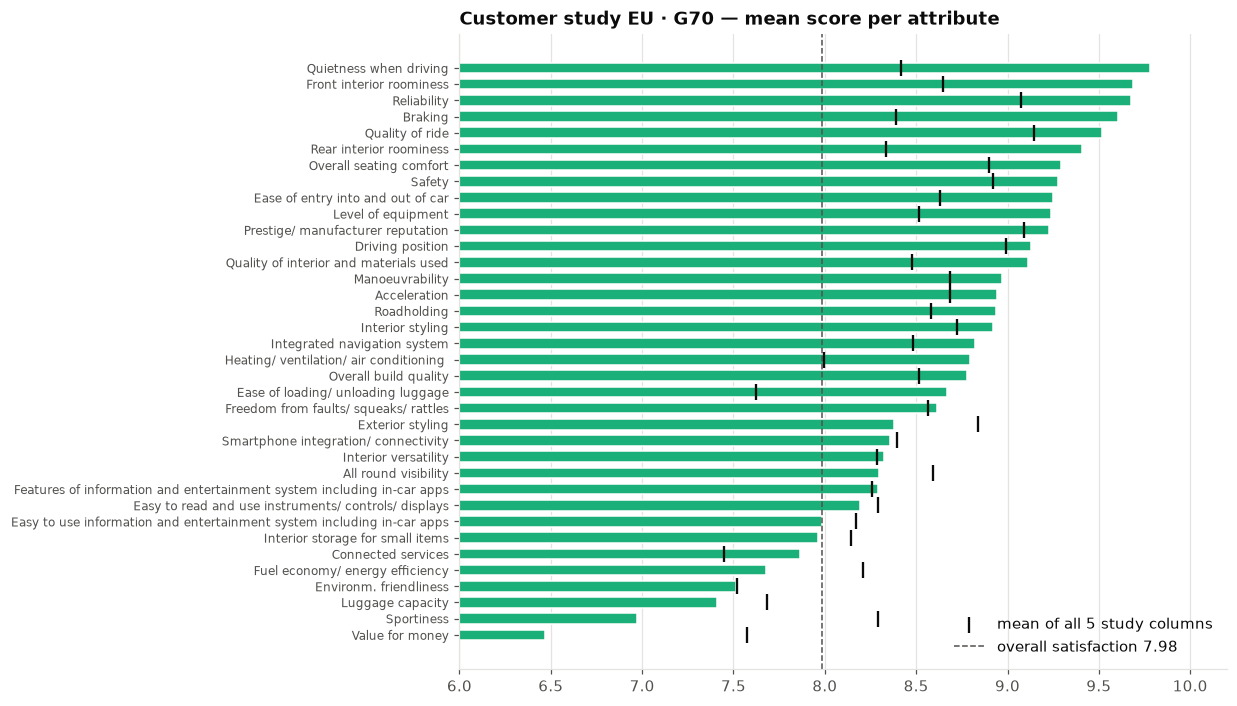

**EU · G70: weakest and strongest attributes** (gap = score minus the mean of the other four columns)

,score,rank (of 36),vs other columns,group
attribute,,,,
Value for money,6.47,36,-1.38,weakest
Sportiness,6.97,35,-1.65,weakest
Luggage capacity,7.41,34,-0.34,weakest
Environm. friendliness,7.51,33,-0.01,weakest
Fuel economy/ energy efficiency,7.68,32,-0.66,weakest
Connected services,7.86,31,+0.51,weakest
Quietness when driving,9.78,1,+1.70,strongest
Front interior roominess,9.69,2,+1.30,strongest
Reliability,9.67,3,+0.75,strongest


In [26]:
study_cneu_profile("G70")

### 5.4 Customer study — US

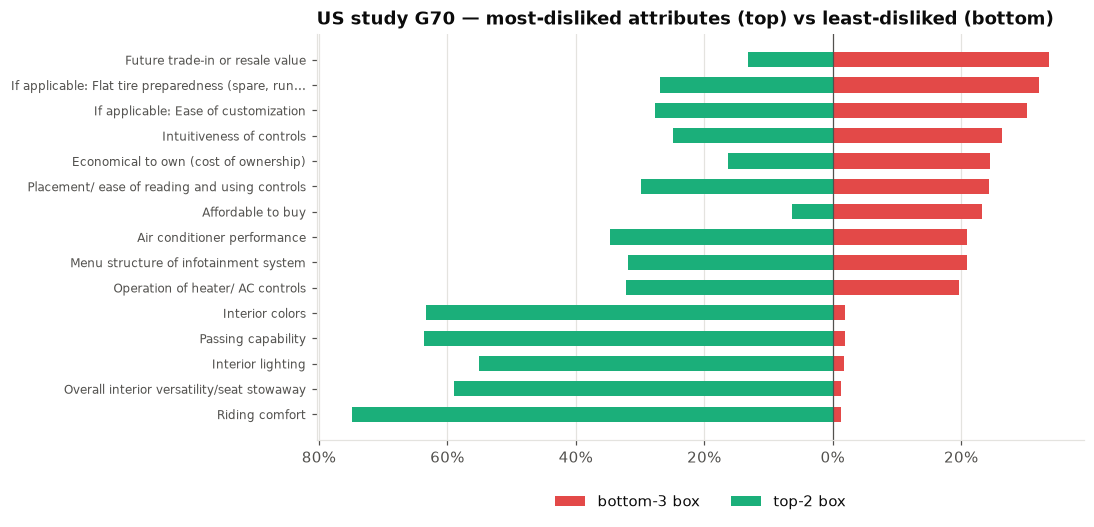

**US G70: lowest weighted mean (1–7)**, with the top-2 gap vs the G60

,mean_1_7,top2,bottom3,top2_vs_other
attribute,,,,
Future trade-in or resale value,3.77,13%,33.7%,-23%
Affordable to buy,3.78,6%,23.2%,-13%
Economical to own (cost of ownership),4.03,16%,24.5%,-12%
"If applicable: Flat tire preparedness (spare, run flat, etc.)",4.22,27%,32.1%,-8%
Price/deal offered,4.25,14%,16.3%,-22%
If applicable: Ease of customization,4.34,28%,30.2%,-16%
Intuitiveness of controls,4.36,25%,26.4%,-17%
Air conditioner performance,4.48,35%,21.0%,-5%
WiFi hotspot in vehicle,4.50,28%,19.5%,-10%


In [27]:
study_us_profile("G70")

### 5.5 Equipment (German catalog)

Only 4 of the 7 models (i7 50xDrive, i7 60xDrive, 740 xDrive, i7 M70 xDrive) have equipment data; 750e, M760e and 740d are listed as "available from November".

In [28]:
equipment_profile("G70")

**Models in the German catalog (7)**

,Fuel / powertrain,Output kW (PS),Electric range / battery,"Consumption / CO2 (WLTP combined, as on price page)",Base price EUR (Fahrzeuggrundpreis)
Model,,,,,
i7 50xDrive,"Vollelektrisch (BEV), Motor: E-Motor, xDrive",335 (455),"621–727 km WLTP; 112,5 kWh net (p. 24)","20,4 kWh/100 km; CO2 ""–""","121.400,– [102.016,81]"
i7 60xDrive,"Vollelektrisch (BEV), E-Motor, xDrive",400 (544),"619–727 km WLTP; 112,5 kWh net (p. 24)","20,5 kWh/100 km; CO2 ""–""","140.100,– [117.731,09]"
i7 M70 xDrive,"Vollelektrisch (BEV), E-Motor, xDrive",500 (680),"611–686 km WLTP; 112,4 kWh net (p. 24)","20,8 kWh/100 km; CO2 ""–""","182.400,- [153.277,31]"
750e xDrive ¹˒⁵,"Plug-in-Hybrid (PHEV), xDrive",360 (489) system ¹˒²; Verbrennungsmotor 230 (313); E-Motor 145 (197),"**Not stated in catalog** (no electric range, battery capacity or charging data for the PHEVs)","17,5–16,0 kWh/100 km + 6,1–5,0 l/100 km; 138–113 g/km; with discharged battery 8,5 l/100 km","133.900,– [112.521,01]"
M760e xDrive ¹˒⁵,"Plug-in-Hybrid (PHEV), xDrive",450 (612) system ¹˒²; Verbrennungsmotor 313 (426); E-Motor 145 (197),**Not stated in catalog**,"18,2–16,7 kWh/100 km + 6,8–5,6 l/100 km; 154–128 g/km; with discharged battery 9,0–8,9 l/100 km","159.900,– [134.369,75]"
740 xDrive,"Benziner with 48 V Mild-Hybrid-Technologie 13 (18) kW (PS), xDrive",294 (400) ²,"– (48 V battery 0,9 kWh gross, p. 25)","8,4 l/100 km; 191 g/km (p. 25: 8,4–7,9 l/100 km; 191–180 g/km)","117.900,– [99.075,63]"
740d xDrive ⁵,"Diesel with 48 V Mild-Hybrid-Technologie 13 (18) kW (PS), xDrive",230 (313) ²,–,"7,2–6,5 l/100 km; 191–172 g/km","122.900,– [103.277,31]"


**Equipment rows per model** (standard + optional equipment sections, 97 items; 3 models have no equipment data)

,i7 50xDrive,i7 60xDrive,i7 M70 xDrive,740 xDrive
standard (S),60,60,72,58
optional (O),22,23,15,21
not offered (–),15,14,10,18


**Standard (S) items per category and model**

model,i7 50xDrive,i7 60xDrive,i7 M70 xDrive,740 xDrive
category,,,,
Antrieb / Fahrdynamik / Fahrwerk,5,5,6,5
Exterieur,7,7,11,7
Fahrerassistenz und Sicherheit,9,9,10,9
"Fahrwerk, Bremsen und Lenkung",0,0,1,0
Interieur,10,10,13,10
Klimakomfort,0,0,1,0
Komfort und Funktionalität,22,22,22,20
Konnektivität und Infotainment,7,7,7,7
Sicht,0,0,1,0


**Trim ladder: 23 items that are standard on some models but not on others**

item i7 50xDrive i7 60xDrive i7 M70 xDrive 740 xDrive
category                         code                                                                                                                     
Exterieur                        1F4                       20" Leichtmetallräder Sternspeiche 905 Bicolor           –           –             –          S
                                 3R8                                    20" Aerodynamikräder 1097 Bicolor           S           S             –          –
                                 1FE         21" M Aerodynamikräder 909 M Multicolor 3D-Glanzschliff mit…           –           –             S          –
                                 760                                              M Hochglanz Shadow Line           –           –             S          –
                                 754                                          M Heckspoiler in Wagenfarbe           –           –             S          –
                                 9T1                                             M Sport Exterieurumfänge           –           –             S          –
                                 420                                               Sonnenschutzverglasung           –           –             S          –
Interieur                        KVSW                                        Kunstleder Veganza | Schwarz           S           S             –          S
                                 VCJL                            BMW M Leder 'Merino' Schwarz | Atlasgrau           –           –             S          –
                                 4D7      Interieurleisten Edelholz Lindenholz Fineline braun, offenporig           S           S             –          S
                                 ?           Interieurleisten Edelholz Fineline schwarz mit Metalleffekt…           –           –             S          –
                                 775                                               M Dachhimmel Anthrazit           –           –             S          –
                                 9T2                                             M Sport Interieurumfänge           –           –             S          –
Antrieb / Fahrdynamik / Fahrwerk                      Steptronic Sport Getriebe Steptronic Sport Getriebe           –           –             –          S
                                       AC-Laden Professional: AC Laden für zuhause und unterwegs (22 kW,…           S           S             S          –
                                 2VS                              Adaptive M Chassis Control Professional           –           –             S          –
Fahrerassistenz und Sicherheit   2PA                                                Radschraubensicherung           –           –             S          –
Komfort und Funktionalität                                                            Standklimatisierung           S           S             S          –
                                                                                BMW IconicSounds Electric           S           S             S          –
Interieur                        775                                               M Dachhimmel Anthrazit           O           O             S          O
Fahrwerk, Bremsen und Lenkung    3M3                                      M Sportbremse, schwarz metallic           O           O             S          O
Sicht                            3DM                      BMW Individual Kristallscheinwerfer Iconic Glow           O           O             S          O
Klimakomfort                     420                                               Sonnenschutzverglasung           O           O             S          O

### 5.6 Key observations: 7 Series

- **Small but growing.** 42k units in 2025, evenly spread across EU, US and CN. It has the strongest planned growth (+24 % to 2030).
- **Loved:** drivetrain, handling, exterior and interior design, interior comfort, space and the automatic doors.
- **Pain points cluster on digital features:** tech overload ("dizzying digital"), infotainment, climate control, Personal eSIM, the operating concept and the My BMW app. In Source C, the OEM smartphone app has the most serious/very serious problem reports.
- **Wants:** wheels and exterior design, panorama roof, interior rear-view mirror, and an auto start-stop switch-off.
- **Studies:** EU G70 scores **value for money 6.47, the lowest cell in the whole CN/EU sheet**, and sportiness 6.97, but it leads on quietness (9.78) and front roominess. China G70 has the highest overall satisfaction (9.64) but is weak on connected services and rear roominess (7.52). That gap matters for a chauffeur-driven market. In the US, cost/resale items and the intuitiveness and placement of controls collect the largest bottom-3 shares.

---
## 6. Cross-series comparison

### 6.1 Customer study: all five CN/EU columns

Same sheet, same scale, so these columns can be compared directly. Colour = deviation from the row mean.

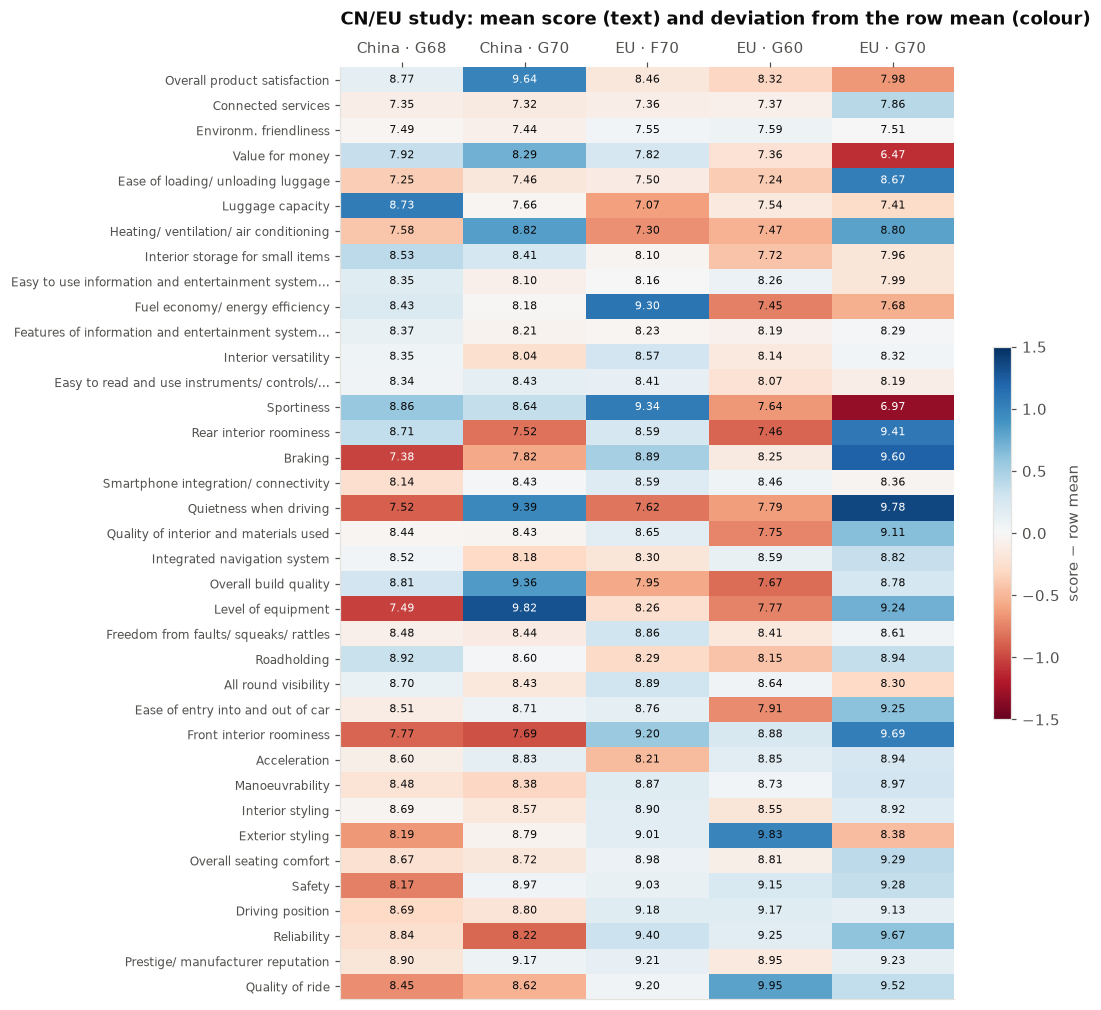

In [29]:
order = ["Overall product satisfaction",
         *study_cneu.drop(index="Overall product satisfaction").mean(axis=1).sort_values().index]
dev = study_cneu.loc[order].sub(study_cneu.loc[order].mean(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(9, 11))
im = ax.imshow(dev.values, cmap="RdBu", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(dev.shape[1]), dev.columns)
ax.set_yticks(range(dev.shape[0]), [short(i, 50) for i in dev.index], fontsize=8)
for (i, j), v in np.ndenumerate(study_cneu.loc[order].values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color=INK if abs(dev.values[i, j]) < 1 else "white")
ax.grid(False)
ax.xaxis.tick_top()
ax.set_title("CN/EU study: mean score (text) and deviation from the row mean (colour)", pad=28)
fig.colorbar(im, ax=ax, shrink=0.4, label="score − row mean")
plt.show()

Attributes that are weak **everywhere** are candidate cross-series requirements; attributes weak in one column only are series- or market-specific.

In [30]:
ranks = study_cneu.drop(index="Overall product satisfaction").rank(ascending=True)  # 1 = weakest
pd.DataFrame({
    "mean score": study_cneu.mean(axis=1),
    "min score": study_cneu.min(axis=1),
    "columns in bottom 8": (ranks <= 8).sum(axis=1),
}).drop(index="Overall product satisfaction").sort_values("mean score").head(12).style.format(
    {"mean score": "{:.2f}", "min score": "{:.2f}"})

,mean score,min score,columns in bottom 8
attribute,,,
Connected services,7.45,7.32,5.000000
Environm. friendliness,7.52,7.44,5.000000
Value for money,7.57,6.47,3.000000
Ease of loading/ unloading luggage,7.62,7.24,4.000000
Luggage capacity,7.68,7.07,4.000000
Heating/ ventilation/ air conditioning,7.99,7.30,3.000000
Interior storage for small items,8.15,7.72,1.000000
Easy to use information and entertainment system including in-car apps,8.17,7.99,1.000000
Fuel economy/ energy efficiency,8.21,7.45,2.000000


### 6.2 US study: 5 Series vs 7 Series

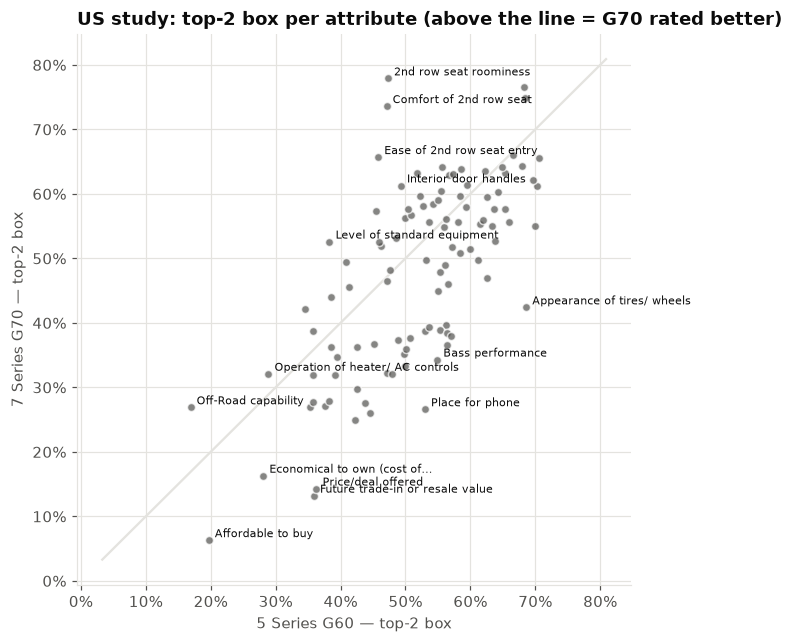

**Largest gaps in top-2 box**

series,G60,G70,G70 − G60
attribute,,,
2nd row seat roominess,47%,78%,31%
Comfort of 2nd row seat,47%,74%,26%
Ease of 2nd row seat entry,46%,66%,20%
Level of standard equipment,38%,53%,14%
Interior door handles,49%,61%,12%
Passenger seat adjustability,45%,57%,12%
Place for phone,53%,27%,-26%
Appearance of tires/ wheels,69%,42%,-26%
Future trade-in or resale value,36%,13%,-23%


In [31]:
us_wide = study_us.pivot(index="attribute", columns="series", values="top2")
us_wide["G70 − G60"] = us_wide["G70"] - us_wide["G60"]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(us_wide["G60"], us_wide["G70"], s=28, color=INK_2, alpha=0.7, edgecolor="white")
lim = [us_wide[["G60", "G70"]].min().min() - 0.03, us_wide[["G60", "G70"]].max().max() + 0.03]
ax.plot(lim, lim, color=GRID, linewidth=1.5, zorder=0)
for attr in pd.concat([us_wide.nlargest(5, "G70 − G60"), us_wide.nsmallest(5, "G70 − G60"),
                       us_wide.nsmallest(4, "G60")]).index.unique():
    ax.annotate(short(attr, 32), (us_wide.loc[attr, "G60"], us_wide.loc[attr, "G70"]), fontsize=7, color=INK,
                xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("5 Series G60 — top-2 box")
ax.set_ylabel("7 Series G70 — top-2 box")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("US study: top-2 box per attribute (above the line = G70 rated better)")
plt.show()
display(Markdown("**Largest gaps in top-2 box**"))
pd.concat([us_wide.nlargest(6, "G70 − G60"), us_wide.nsmallest(6, "G70 − G60")]).style.format("{:.0%}")

### 6.3 Feedback topics across series

Topic share = rows of the topic / all classified rows of the series, so series with different sample sizes can be compared.
Remember the samples differ in market (F70: GB/JP reviews; G60/G70: mostly US, several channels).

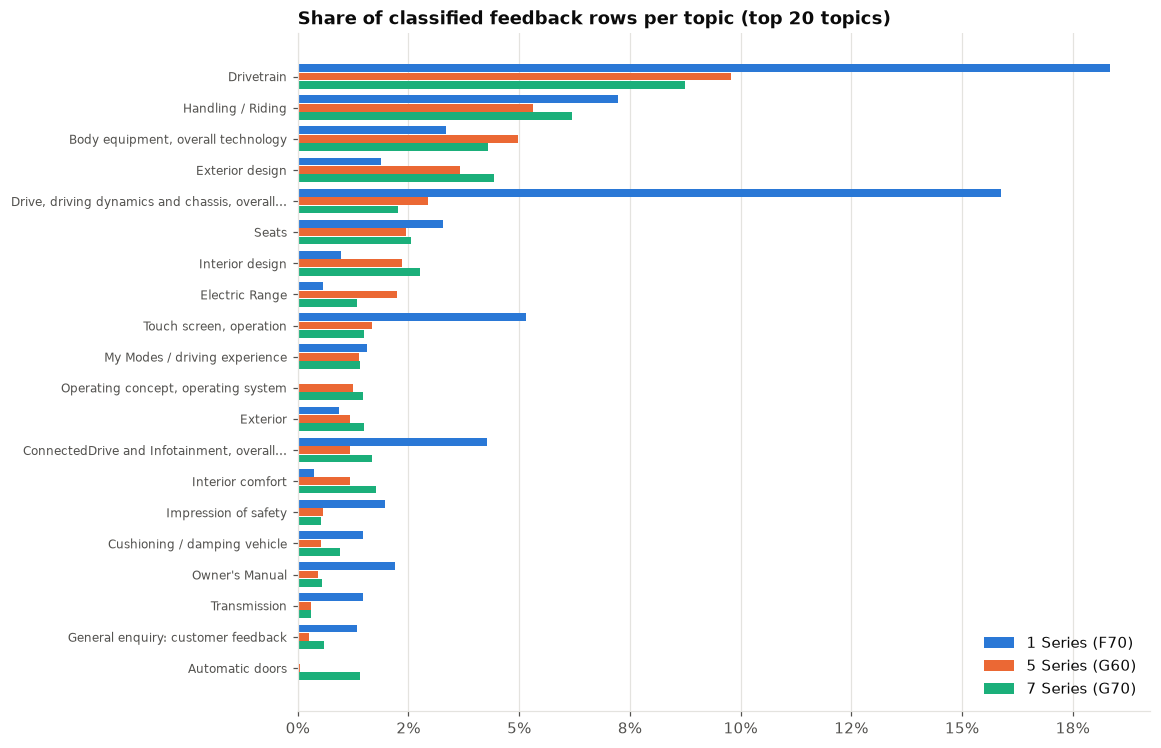

In [32]:
tt = fb_rows[fb_rows["classified"]]
share = (tt.groupby(["topic", "series"]).size().unstack(fill_value=0) / tt.groupby("series").size())
top_topics = share.max(axis=1).nlargest(20).index
s20 = share.loc[top_topics].sort_values("G60")
fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(s20))
for i, code in enumerate(SERIES):
    ax.barh(y + (1 - i) * 0.27, s20[code], height=0.25, color=SERIES[code]["color"], label=f"{SERIES[code]['name']} ({code})")
ax.set_yticks(y, [short(i, 50) for i in s20.index], fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Share of classified feedback rows per topic (top 20 topics)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

In [33]:
net = pd.DataFrame({code: topic_table(code, min_rows=20)["net_sentiment"] for code in SERIES})
common = net.dropna()
display(Markdown(f"**Net sentiment for the {len(common)} topics with ≥ 20 rows in every series** (−1 = only criticism, +1 = only praise)"))
common.sort_values("G60").style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1)

**Net sentiment for the 22 topics with ≥ 20 rows in every series** (−1 = only criticism, +1 = only praise)

,F70,G60,G70
topic,,,
Vehicle key,-1.00,-0.80,-0.81
"Vehicle, climatization",-0.81,-0.69,-0.91
Instrument panel,-0.50,-0.64,-0.57
Braking,-0.52,-0.63,-0.65
Owner's Manual,-0.91,-0.50,-0.82
Navigation,-0.74,-0.37,-0.33
"ConnectedDrive and Infotainment, overall technology",-0.58,-0.28,-0.17
Wheels / tires,-0.93,-0.13,-0.62
"Audio mode, sound",-0.67,-0.13,+0.10


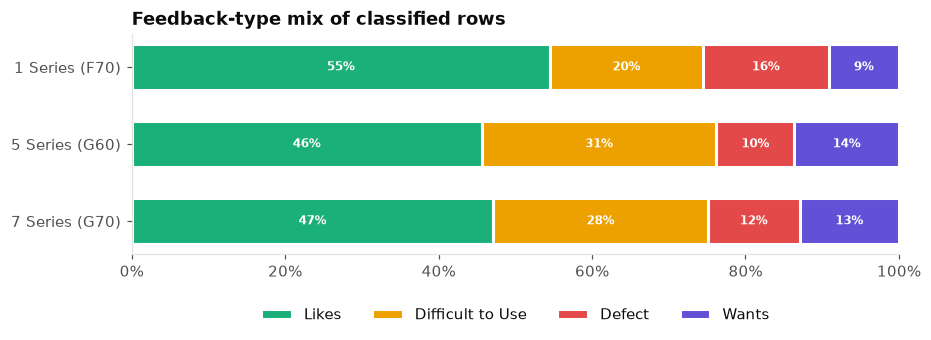

In [34]:
pain_share = pd.DataFrame({
    code: fb_rows[(fb_rows.series == code) & fb_rows.classified].groupby("ftype").size()
    / fb_rows[(fb_rows.series == code) & fb_rows.classified & fb_rows.ftype.notna()].shape[0]
    for code in SERIES
}).reindex(FEEDBACK_TYPES)
fig, ax = plt.subplots(figsize=(9, 2.6))
left = np.zeros(3)
labels = [f"{SERIES[c]['name']} ({c})" for c in SERIES][::-1]
for ft in FEEDBACK_TYPES:
    vals = pain_share.loc[ft].values[::-1]
    ax.barh(labels, vals, left=left, color=TYPE_COLORS[ft], label=ft, height=0.6, edgecolor="white", linewidth=2)
    for yy, (l, v) in enumerate(zip(left, vals)):
        ax.text(l + v / 2, yy, f"{v:.0%}", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    left += vals
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1)
ax.set_title("Feedback-type mix of classified rows")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(False)
plt.show()

### 6.4 Powertrain-specific topics (5 and 7 Series)

Which topics are over-represented in BEV feedback compared with ICE? Lift = topic share among BEV rows / topic share among ICE rows (with +1 smoothing on the counts).

In [35]:
for code in ["G60", "G70"]:
    r = fb_rows[(fb_rows.series == code) & fb_rows.classified]
    sh = r.groupby(["topic", "powertrain"]).size().unstack(fill_value=0)
    counts = sh.copy()
    sh = (sh + 1) / (sh + 1).sum()  # +1 smoothing so BEV-only topics (e.g. Electric Range) still get a finite lift
    lift = (sh["BEV"] / sh["ICE"]).rename("BEV/ICE lift")
    out = pd.DataFrame({"BEV rows": counts["BEV"], "ICE rows": counts["ICE"], "PHEV rows": counts["PHEV"], "BEV/ICE lift": lift})
    out = out[(out["BEV rows"] >= 15)].sort_values("BEV/ICE lift", ascending=False).head(10)
    display(Markdown(f"**{SERIES[code]['name']} ({code}): topics most over-represented in BEV feedback**"))
    display(out.style.format({"BEV/ICE lift": "{:.1f}×"}))

**5 Series (G60): topics most over-represented in BEV feedback**

,BEV rows,ICE rows,PHEV rows,BEV/ICE lift
topic,,,,
Electric Range,74,0,22,113.4×
Public charging / external providers,47,1,1,36.3×
"Wallbox, charging / home charging",16,0,3,25.7×
Opening/closing charging socket cover,15,0,2,24.2×
Charge high-voltage battery,25,2,8,13.1×
Highway assistant,21,12,5,2.6×
Interior comfort,22,21,8,1.6×
"Audio mode, sound",18,20,8,1.4×
My Modes / driving experience,25,28,6,1.4×


**7 Series (G70): topics most over-represented in BEV feedback**

,BEV rows,ICE rows,PHEV rows,BEV/ICE lift
topic,,,,
Electric Range,44,0,10,89.9×
Public charging / external providers,29,0,0,60.0×
Charge high-voltage battery,16,0,7,34.0×
Personal eSIM,21,15,4,2.7×
Navigation,16,14,3,2.3×
"ConnectedDrive and Infotainment, overall technology",26,35,6,1.5×
"Audio mode, sound",16,22,2,1.5×
My Modes / driving experience,18,30,9,1.2×
Interior comfort,22,46,3,1.0×


### 6.5 Equipment breadth across series

Standard-equipment rows that are standard on every covered model, per series. A rough proxy for how much each car
ships with in Germany. The catalogs differ in granularity, so treat the numbers as indicative only.

In [36]:
rows = []
for code, (models, items, model_names) in options.items():
    covered = [m for m in model_names if (items[m] != "n/a").any()]
    std = items[items["section"] == "standard"]
    opt = items[items["section"] == "optional"]
    rows.append({
        "series": f"{SERIES[code]['name']} ({code})",
        "catalog models": len(model_names),
        "models with equipment data": len(covered),
        "standard-equipment rows": len(std),
        "…standard on every model": int((std[covered] == "S").all(axis=1).sum()),
        "optional-equipment rows": len(opt),
        "…optional on every model": int((opt[covered] == "O").all(axis=1).sum()),
    })
pd.DataFrame(rows).set_index("series")

,catalog models,models with equipment data,standard-equipment rows,…standard on every model,optional-equipment rows,…optional on every model
series,,,,,,
1 Series (F70),6,6,39,24,22,16
5 Series (G60),10,10,48,28,24,18
7 Series (G70),7,4,73,54,24,13


## 7. Summary: themes that show up across series

| Theme | Evidence | Series |
| --- | --- | --- |
| **Controls and operating concept** | Touchscreen/menu complaints and Wants in feedback; low US scores for heater/AC controls, menu structure and intuitiveness of controls | All three; strongest in F70 feedback and G70 US study |
| **Connected services and apps** | Lowest or near-lowest CN/EU study score in every column (7.3–7.9); app, eSIM and CarPlay pain points in G60/G70 feedback | All |
| **Luggage and practicality** | Luggage loading/capacity near the bottom in every CN/EU column; interior storage weak in the US G60 study | All, especially F70 and G60 |
| **Range and charging (BEV)** | Electric range and public charging over-represented in BEV feedback | G60, G70 |
| **Value perception** | Value for money is weak in the EU (G70: 6.47); affordability and resale are the worst US G70 items | G60, G70 |
| **Driving experience = core strength** | Drivetrain/handling dominate Likes; ride, reliability and sportiness score highly | All (protect in the successor) |

These are signals, not tested results. Feedback samples are unbalanced by market (no CN or DE voices), and the studies give no sample sizes.